<a href="https://colab.research.google.com/github/IstaftyKevaYuftika/RegresiLinear_Kelas5B_Kelompok7/blob/main/RegresiLinear_Kelas5B_kelompok7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Regresi Linear — Bike Sharing Demand**

**Mata Kuliah:** Pembelajaran Mesin | **Kelas:** 5B | **Kelompok: 7**


---

**Dataset:** Bike Sharing Demand (Kaggle) — file `train.csv`.
**Target regresi:** `count` (total penyewaan sepeda per jam).
**Fokus latihan:** manipulasi data waktu (`datetime`). Informasi jam, hari, bulan, dan musim diekstrak dari kolom `datetime`, lalu dilihat korelasinya dengan faktor cuaca.

Alur notebook:
**EDA → Preprocessing & Feature Engineering → Pemodelan Regresi Linear → Evaluasi**


In [5]:
import pandas as pd
import os

file_path = 'sample_data/content/train.csv'

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "File 'train.csv' tidak ditemukan di /content/. "
        "Silakan unggah file 'train.csv' terlebih dahulu melalui panel file di sebelah kiri Colab."
    )

df = pd.read_csv(file_path)

## **Inspeksi Awal Data (Initial Data Inspection)**

### Tujuan
Memahami struktur, ukuran, tipe data, dan isi awal dataset **Bike Sharing Demand** sebelum analisis lanjutan.

Dataset ini mencatat penyewaan sepeda per jam. Kolom-kolomnya:

| Kolom | Keterangan |
|---|---|
| `datetime` | Tanggal dan jam (waktu) pencatatan |
| `season` | 1 = semi, 2 = panas, 3 = gugur, 4 = dingin |
| `holiday` | 1 jika hari libur, 0 jika bukan |
| `workingday` | 1 jika hari kerja (bukan akhir pekan/libur), 0 jika bukan |
| `weather` | 1 = cerah, 2 = berkabut/mendung, 3 = hujan/salju ringan, 4 = hujan/salju lebat |
| `temp` | Suhu (°C) |
| `atemp` | Suhu yang dirasakan (°C) |
| `humidity` | Kelembapan relatif |
| `windspeed` | Kecepatan angin |
| `casual` | Jumlah penyewa non-terdaftar |
| `registered` | Jumlah penyewa terdaftar |
| `count` | Total penyewaan (**target**) = `casual` + `registered` |

In [6]:
print("--- 5 Baris Pertama Data ---")
display(df.head())

print("\n--- 5 Baris Terakhir Data ---")
display(df.tail())

print(f"\nDimensi dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

print("\n--- Informasi Dataset (Tipe Data & Non-Null) ---")
df.info()

print("\n--- Daftar Nama Kolom ---")
print(df.columns.tolist())

--- 5 Baris Pertama Data ---


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1



--- 5 Baris Terakhir Data ---


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
10881,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336
10882,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241
10883,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168
10884,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129
10885,2012-12-19 23:00:00,4,0,1,1,13.12,16.665,66,8.9981,4,84,88



Dimensi dataset: 10886 baris, 12 kolom

--- Informasi Dataset (Tipe Data & Non-Null) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB

--- Daftar Nama Kolom ---
['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']


### Penjelasan
1. `pd.read_csv()` memuat data ke DataFrame `df`.
2. `df.head()` dan `df.tail()` menunjukkan contoh baris awal dan akhir.
3. `df.shape` menunjukkan jumlah baris dan kolom (versi Kaggle `train.csv` umumnya **10.886 baris dan 12 kolom**).
4. `df.info()` menunjukkan bahwa `datetime` masih bertipe **object (teks)**, sehingga harus diubah ke tipe `datetime` agar bisa diekstrak jam, hari, bulan, dan tahunnya.
5. Kolom `season`, `holiday`, `workingday`, dan `weather` bertipe angka, tetapi sebenarnya **kategorikal** (kode kategori, bukan besaran).

## **Pengecekan Kualitas Data Dasar (Basic Data Quality Checks)**

--- Pengecekan Missing Values ---


,Jumlah Missing,Persentase (%)
datetime,0,0.0
season,0,0.0
holiday,0,0.0
workingday,0,0.0
weather,0,0.0
temp,0,0.0
atemp,0,0.0
humidity,0,0.0
windspeed,0,0.0
casual,0,0.0


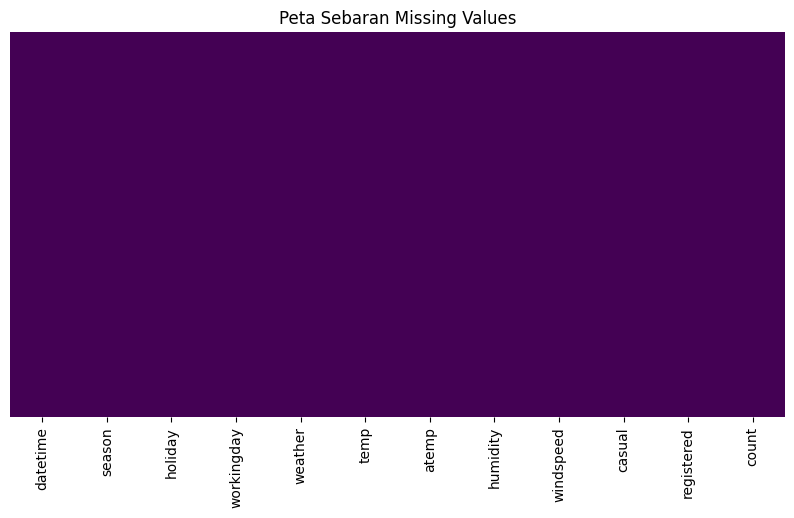


--- Pengecekan Data Duplikat ---
Jumlah baris duplikat identik: 0

--- Cek Konsistensi: count = casual + registered ---
Semua baris konsisten: True


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Pengecekan Missing Values ---")
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_table = pd.concat([missing_data, missing_percent], axis=1, keys=['Jumlah Missing', 'Persentase (%)'])
display(missing_table)

plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.title('Peta Sebaran Missing Values')
plt.show()

print("\n--- Pengecekan Data Duplikat ---")
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat identik: {jumlah_duplikat}")
if jumlah_duplikat > 0:
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)))

print("\n--- Cek Konsistensi: count = casual + registered ---")
print("Semua baris konsisten:", (df['count'] == df['casual'] + df['registered']).all())

### Ringkasan Pengecekan Kualitas Data
* **Missing value:** dataset ini umumnya **tidak memiliki nilai kosong**, sehingga tidak diperlukan imputasi (berbeda dengan dataset Housing yang punya missing value).
* **Duplikat:** tidak ditemukan baris duplikat (periksa hasil sel di atas).
* **Temuan penting (data leakage):** `count` selalu sama dengan `casual + registered`. Jika `casual` dan `registered` dipakai sebagai fitur, model hanya "menjumlahkan" keduanya dan hasilnya terlihat sangat bagus secara semu. Kedua kolom ini **harus dibuang dari fitur** pada tahap preprocessing. Pada data uji Kaggle yang sebenarnya, kedua kolom ini juga tidak tersedia.

## **Klasifikasi Data: Kosong, Kotor, dan Bersih**

Setiap baris data dikelompokkan ke dalam **tiga kategori** (saling lepas, dengan prioritas Kosong → Kotor → Bersih):

| Kategori | Definisi | Contoh pada dataset ini |
|---|---|---|
| **Data Kosong** | Ada sel yang tidak terisi (*missing value* / NaN) | Nilai `NaN` pada kolom apa pun |
| **Data Kotor** | Sel terisi, tetapi **nilainya salah, tidak masuk akal, kontradiktif, atau berulang** | Baris duplikat, `humidity = 0`, `windspeed = 0` (diduga tidak terukur), kode `season`/`weather` di luar rentang, `holiday = 1` tetapi `workingday = 1`, `count` tidak sama dengan `casual + registered`, suhu tidak wajar |
| **Data Bersih** | Terisi lengkap, valid, dan konsisten | Baris yang lolos semua pemeriksaan di atas |

> **Beda kosong vs kotor:** data *kosong* = nilainya **tidak ada**. Data *kotor* = nilainya **ada tetapi salah**.
>
> **Outlier bukan otomatis data kotor.** Jam sibuk dengan `count` sangat tinggi adalah nilai yang valid, jadi tidak dihitung sebagai data kotor (ditangani lewat transformasi log pada tahap preprocessing).

========== KLASIFIKASI BARIS (data asli) ==========


,Jumlah baris,Persentase (%)
Kosong,0,0.00
Kotor,1335,12.26
Bersih,9551,87.74



========== RINCIAN DATA KOTOR PER JENIS MASALAH ==========


,Jumlah baris,Persentase (%)
Baris duplikat,0,0.00
Kode kategori di luar rentang valid,0,0.00
Kontradiksi holiday=1 & workingday=1,0,0.00
count negatif / != casual+registered,0,0.00
Suhu tidak wajar (<-10 atau >45 C),0,0.00
humidity <= 0 atau > 100,22,0.20
windspeed = 0 (diduga tidak terukur),1313,12.06



========== RINCIAN DATA KOSONG PER KOLOM ==========


,Jumlah NaN


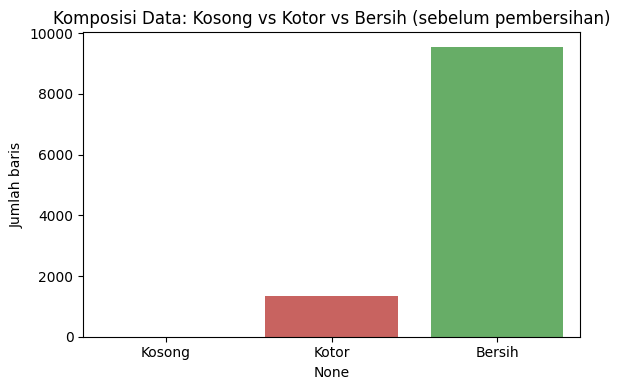


Contoh baris data kotor:


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [8]:
import numpy as np

df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')

def cek_kotor(d):
    # Mengembalikan dict {nama_masalah: mask boolean} untuk data kotor
    return {
        'Baris duplikat'                          : d.duplicated(keep='first'),
        'Kode kategori di luar rentang valid'     : (d['season'].notnull() & ~d['season'].isin([1, 2, 3, 4])) |
                                                    (d['weather'].notnull() & ~d['weather'].isin([1, 2, 3, 4])) |
                                                    (d['holiday'].notnull() & ~d['holiday'].isin([0, 1])) |
                                                    (d['workingday'].notnull() & ~d['workingday'].isin([0, 1])),
        'Kontradiksi holiday=1 & workingday=1'    : (d['holiday'] == 1) & (d['workingday'] == 1),
        'count negatif / != casual+registered'    : (d['count'] < 0) | (d['count'] != d['casual'] + d['registered']),
        'Suhu tidak wajar (<-10 atau >45 C)'      : (d['temp'] < -10) | (d['temp'] > 45) | (d['atemp'] < -10) | (d['atemp'] > 50),
        'humidity <= 0 atau > 100'                : (d['humidity'] <= 0) | (d['humidity'] > 100),
        'windspeed = 0 (diduga tidak terukur)'    : d['windspeed'] <= 0,
    }

# ---- Audit data ASLI ----
kosong = df.isnull().any(axis=1)
masalah = cek_kotor(df)
kotor_any = pd.concat(masalah.values(), axis=1).any(axis=1)

label = np.where(kosong, 'Kosong', np.where(kotor_any, 'Kotor', 'Bersih'))
ringkasan = pd.Series(label).value_counts().reindex(['Kosong', 'Kotor', 'Bersih']).fillna(0).astype(int)
ringkasan_df = pd.DataFrame({'Jumlah baris': ringkasan,
                             'Persentase (%)': (ringkasan / len(df) * 100).round(2)})

print("========== KLASIFIKASI BARIS (data asli) ==========")
display(ringkasan_df)

print("\n========== RINCIAN DATA KOTOR PER JENIS MASALAH ==========")
rincian = pd.DataFrame({'Jumlah baris': {k: int(v.sum()) for k, v in masalah.items()}})
rincian['Persentase (%)'] = (rincian['Jumlah baris'] / len(df) * 100).round(2)
display(rincian)

print("\n========== RINCIAN DATA KOSONG PER KOLOM ==========")
display(df.isnull().sum().to_frame('Jumlah NaN').query('`Jumlah NaN` > 0'))

plt.figure(figsize=(6, 4))
sns.barplot(x=ringkasan_df.index, y=ringkasan_df['Jumlah baris'], hue=ringkasan_df.index,
            palette={'Kosong': '#f0ad4e', 'Kotor': '#d9534f', 'Bersih': '#5cb85c'}, legend=False)
plt.title('Komposisi Data: Kosong vs Kotor vs Bersih (sebelum pembersihan)')
plt.ylabel('Jumlah baris')
plt.tight_layout()
plt.show()

print("\nContoh baris data kotor:")
display(df[kotor_any & ~kosong].head())

### Pembersihan Data

Perlakuan untuk setiap jenis masalah:

| Masalah | Perlakuan | Alasan |
|---|---|---|
| Data kosong (NaN) | Diisi **median** kolomnya | Median tahan terhadap nilai ekstrem |
| Baris duplikat | **Dihapus** (sisakan 1) | Menghindari pencatatan ganda |
| `humidity` = 0 / > 100 | Dianggap tidak valid → diganti **median** | Kelembapan 0% tidak realistis, kemungkinan sensor tidak mencatat |
| `windspeed` = 0 | Dianggap tidak terukur → diganti **median** dari nilai windspeed yang valid | Angin tepat 0 pada jumlah baris sebanyak ini tidak wajar |
| Kode kategori salah / kontradiksi / `count` tidak konsisten / suhu tidak wajar | Baris **dihapus** | Tidak bisa diperbaiki dengan aman |

In [9]:
df_asli = df.copy()   # simpan data asli untuk perbandingan visual
df_bersih = df.drop_duplicates().copy()

# Buang baris yang tidak bisa diperbaiki (kategori salah, kontradiksi, count tidak konsisten, suhu tidak wajar)
m = cek_kotor(df_bersih)
baris_dibuang = (m['Kode kategori di luar rentang valid'] |
                 m['Kontradiksi holiday=1 & workingday=1'] |
                 m['count negatif / != casual+registered'] |
                 m['Suhu tidak wajar (<-10 atau >45 C)'])
df_bersih = df_bersih[~baris_dibuang].copy()

# Nilai tidak valid pada humidity & windspeed -> dijadikan NaN dulu, lalu diimputasi
df_bersih.loc[(df_bersih['humidity'] <= 0) | (df_bersih['humidity'] > 100), 'humidity'] = np.nan
df_bersih.loc[df_bersih['windspeed'] <= 0, 'windspeed'] = np.nan

# Imputasi median untuk semua kolom numerik yang masih kosong
for kolom in df_bersih.select_dtypes(include='number').columns:
    if df_bersih[kolom].isnull().any():
        df_bersih[kolom] = df_bersih[kolom].fillna(df_bersih[kolom].median())

df_bersih = df_bersih.dropna(subset=['datetime']).reset_index(drop=True)

# ---- Audit ulang data SETELAH pembersihan ----
kosong2 = df_bersih.isnull().any(axis=1)
masalah2 = cek_kotor(df_bersih)
kotor2 = pd.concat(masalah2.values(), axis=1).any(axis=1)
label2 = np.where(kosong2, 'Kosong', np.where(kotor2, 'Kotor', 'Bersih'))
ringkasan2 = pd.Series(label2).value_counts().reindex(['Kosong', 'Kotor', 'Bersih']).fillna(0).astype(int)

perbandingan = pd.DataFrame({'Sebelum': ringkasan, 'Sesudah': ringkasan2})
perbandingan['% Sebelum'] = (perbandingan['Sebelum'] / len(df) * 100).round(2)
perbandingan['% Sesudah'] = (perbandingan['Sesudah'] / len(df_bersih) * 100).round(2)

print("========== PERBANDINGAN SEBELUM vs SESUDAH PEMBERSIHAN ==========")
print(f"Jumlah baris: {len(df)} -> {len(df_bersih)}")
display(perbandingan)

# Gunakan data bersih untuk seluruh tahap berikutnya
df = df_bersih.copy()
print("\nSeluruh analisis selanjutnya memakai data bersih. Dimensi:", df.shape)

========== PERBANDINGAN SEBELUM vs SESUDAH PEMBERSIHAN ==========
Jumlah baris: 10886 -> 10886


,Sebelum,Sesudah,% Sebelum,% Sesudah
Kosong,0,0,0.00,0.0
Kotor,1335,0,12.26,0.0
Bersih,9551,10886,87.74,100.0



Seluruh analisis selanjutnya memakai data bersih. Dimensi: (10886, 12)


### Visualisasi Sebelum vs Sesudah Pembersihan

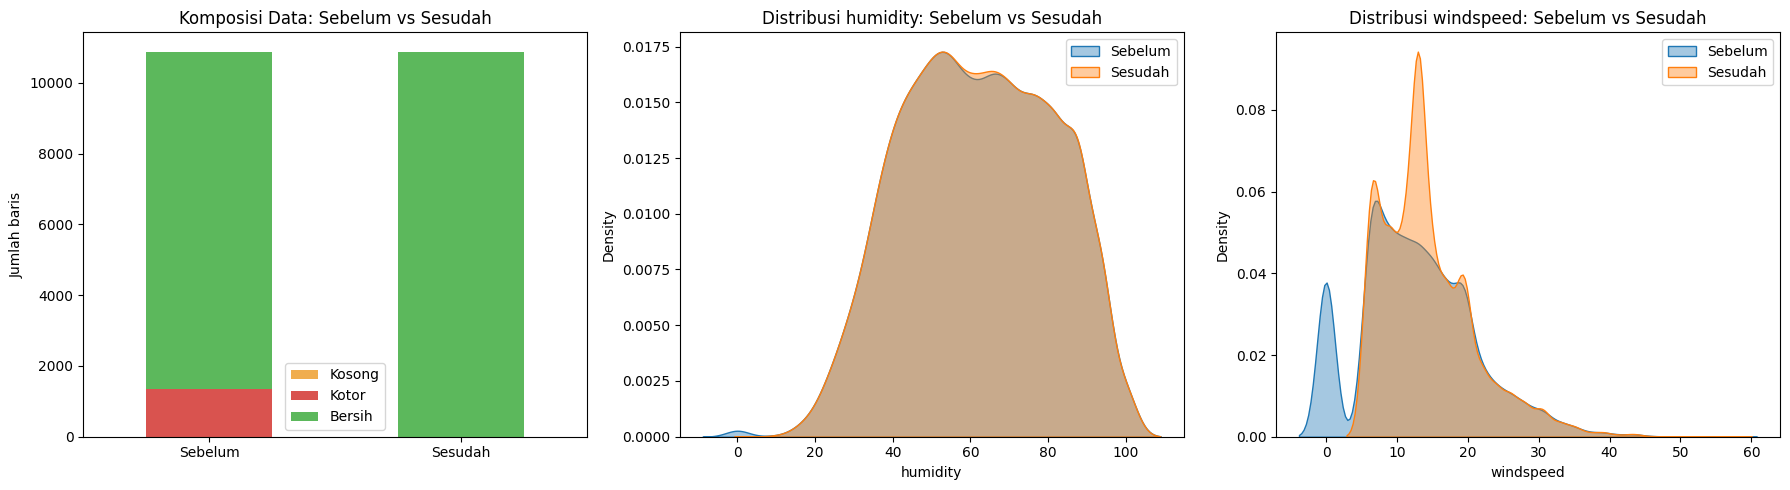

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Komposisi kosong / kotor / bersih
perb = perbandingan[['Sebelum', 'Sesudah']]
perb.T.plot(kind='bar', stacked=True, ax=axes[0], color=['#f0ad4e', '#d9534f', '#5cb85c'])
axes[0].set_title('Komposisi Data: Sebelum vs Sesudah')
axes[0].set_ylabel('Jumlah baris')
axes[0].set_xticklabels(['Sebelum', 'Sesudah'], rotation=0)

# 2 & 3. Distribusi humidity dan windspeed sebelum vs sesudah
for ax, kolom in zip(axes[1:], ['humidity', 'windspeed']):
    sns.kdeplot(df_asli[kolom], ax=ax, label='Sebelum', fill=True, alpha=0.4)
    sns.kdeplot(df[kolom], ax=ax, label='Sesudah', fill=True, alpha=0.4)
    ax.set_title(f'Distribusi {kolom}: Sebelum vs Sesudah')
    ax.legend()

plt.tight_layout()
plt.show()

### Ringkasan Klasifikasi & Pembersihan Data
* Tabel **Sebelum** menunjukkan komposisi data *kosong*, *kotor*, dan *bersih* pada dataset asli. Pada dataset Bike Sharing Demand versi Kaggle, umumnya **tidak ada data kosong**, tetapi terdapat **data kotor** (terutama `windspeed = 0` dan `humidity = 0`) yang tampak normal bila hanya dicek dengan `isnull()`.
* Hal ini menunjukkan bahwa **"tidak ada missing value" tidak sama dengan "data sudah bersih"**.
* Tabel **Sesudah** menunjukkan seluruh baris sudah berstatus *Bersih* (kosong = 0, kotor = 0), sehingga aman dipakai untuk EDA dan pemodelan.
* *(Isi dengan angka aktual dari hasil sel di atas: berapa baris kosong, kotor, dan bersih sebelum pembersihan.)*

## **Statistik Deskriptif (Descriptive Statistics)**

In [11]:
print("--- Statistik Deskriptif untuk Kolom Numerik ---")
display(df.describe())

print("\n--- Distribusi Kategori ---")
for k in ['season', 'holiday', 'workingday', 'weather']:
    print(f"\n{k}:")
    print(df[k].value_counts().sort_index())

--- Statistik Deskriptif untuk Kolom Numerik ---


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2011-12-27 05:56:22.399411968,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,62.011758,14.367131,36.021955,155.552177,191.574132
min,2011-01-01 00:00:00,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,8.000000,6.003200,0.000000,0.000000,1.000000
25%,2011-07-02 07:15:00,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,8.998100,4.000000,36.000000,42.000000
50%,2012-01-01 20:30:00,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,2012-07-01 12:45:00,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,2012-12-19 23:00:00,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000
std,NaN,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.042448,6.666717,49.960477,151.039033,181.144454



--- Distribusi Kategori ---

season:
season
1    2686
2    2733
3    2733
4    2734
Name: count, dtype: int64

holiday:
holiday
0    10575
1      311
Name: count, dtype: int64

workingday:
workingday
0    3474
1    7412
Name: count, dtype: int64

weather:
weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64


### Ringkasan Statistik Deskriptif
* `count` memiliki rata-rata yang jauh lebih besar dari median dan nilai maksimum yang jauh di atas kuartil ketiga. Hal ini menunjukkan distribusi **miring ke kanan (right-skewed)**: sebagian besar jam memiliki penyewaan rendah, sementara beberapa jam sibuk sangat tinggi.
* Setelah pembersihan, `humidity` dan `windspeed` tidak lagi memiliki nilai 0 (nilai 0 sebelumnya dianggap data kotor/tidak terukur dan sudah diimputasi dengan median).
* Kategori `weather = 4` (cuaca ekstrem) hanya muncul sangat sedikit (biasanya hanya 1 baris), sehingga informasinya terbatas.
* Skala antar kolom berbeda (misalnya `temp` puluhan, `humidity` ratusan), sehingga **scaling** diperlukan pada tahap preprocessing.

## **Analisis Univariat (Univariate Analysis)**

### Analisis Univariat untuk Kolom Numerik ###


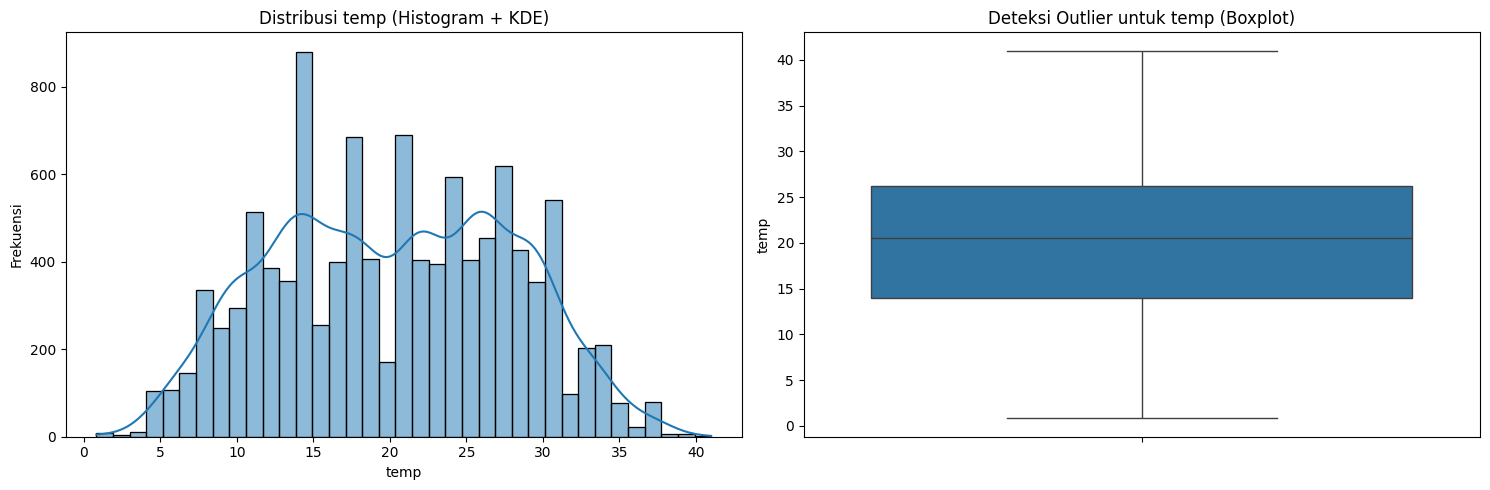

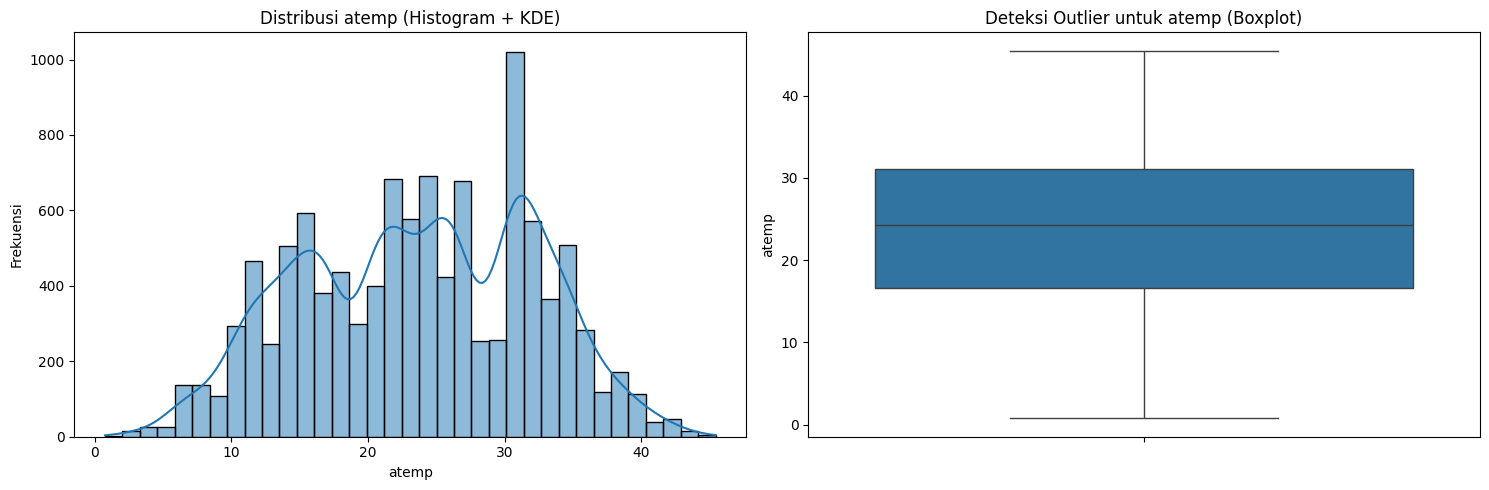

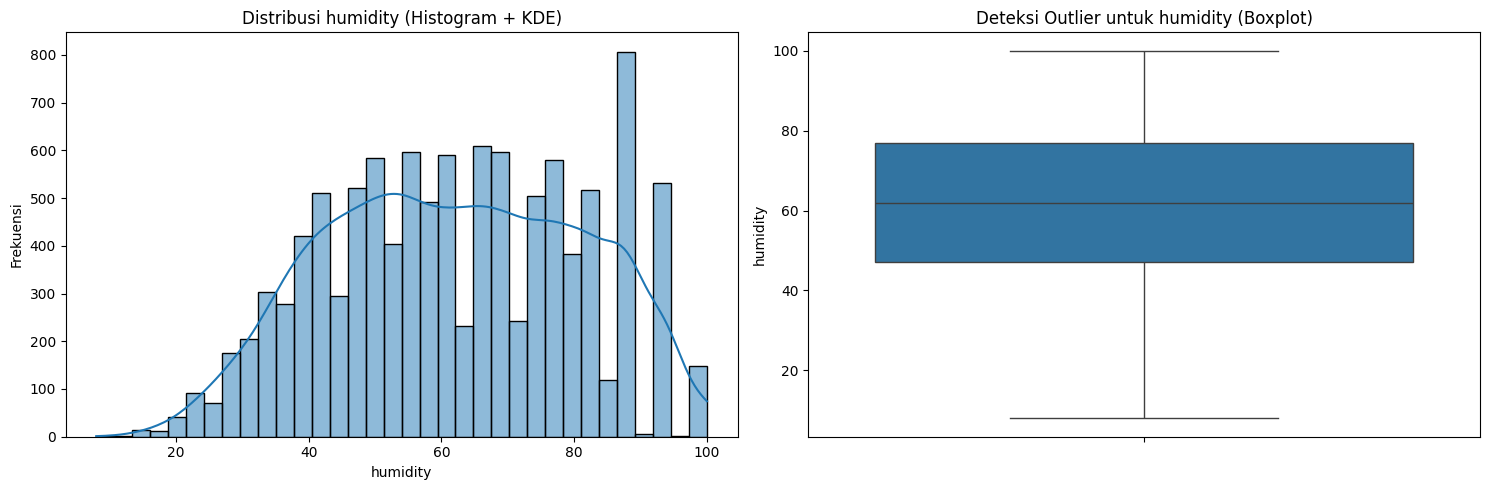

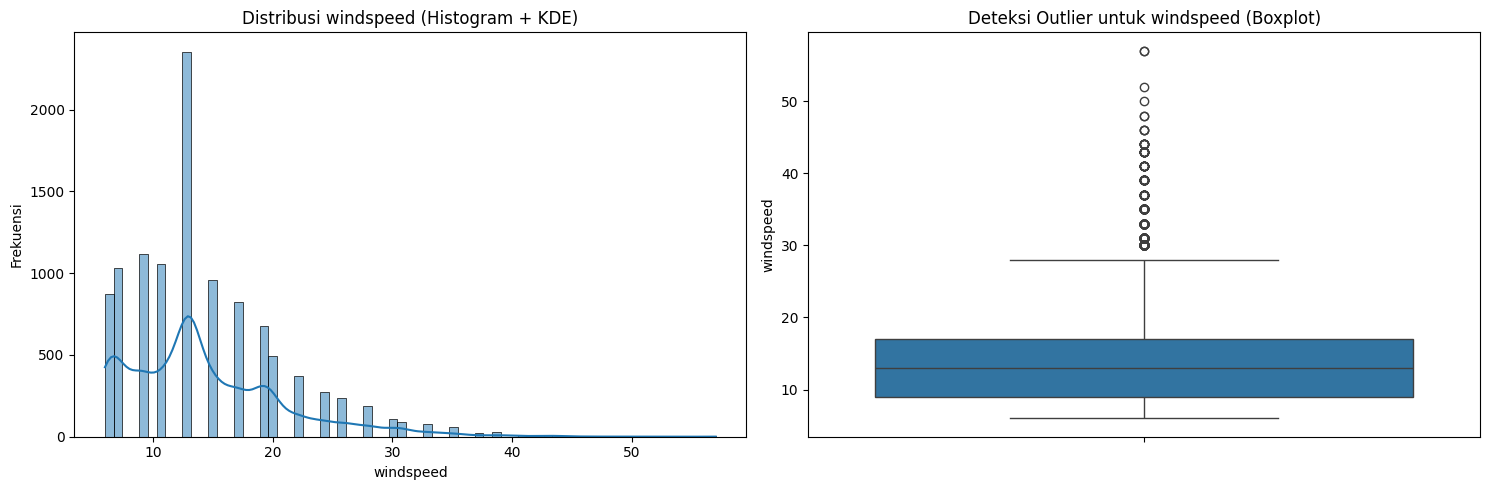

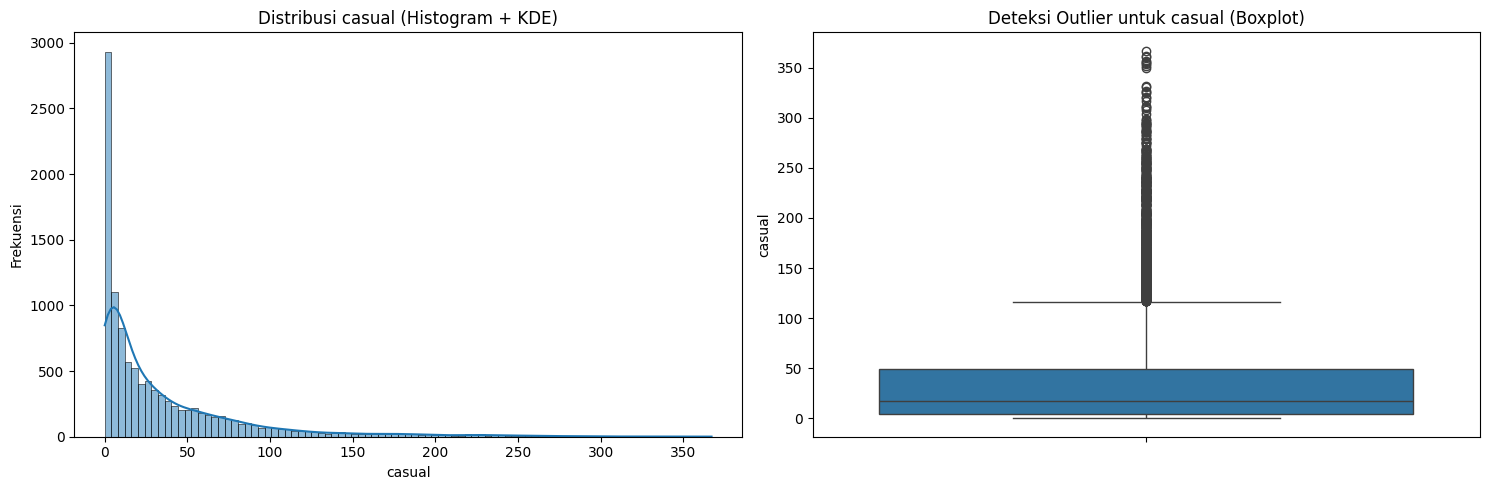

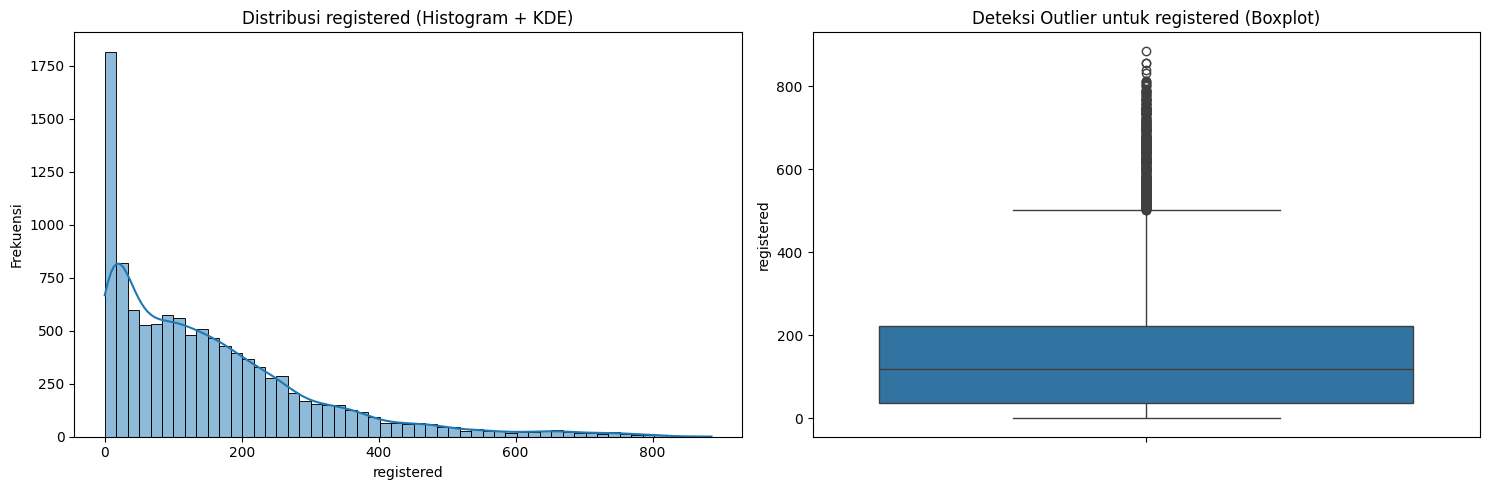

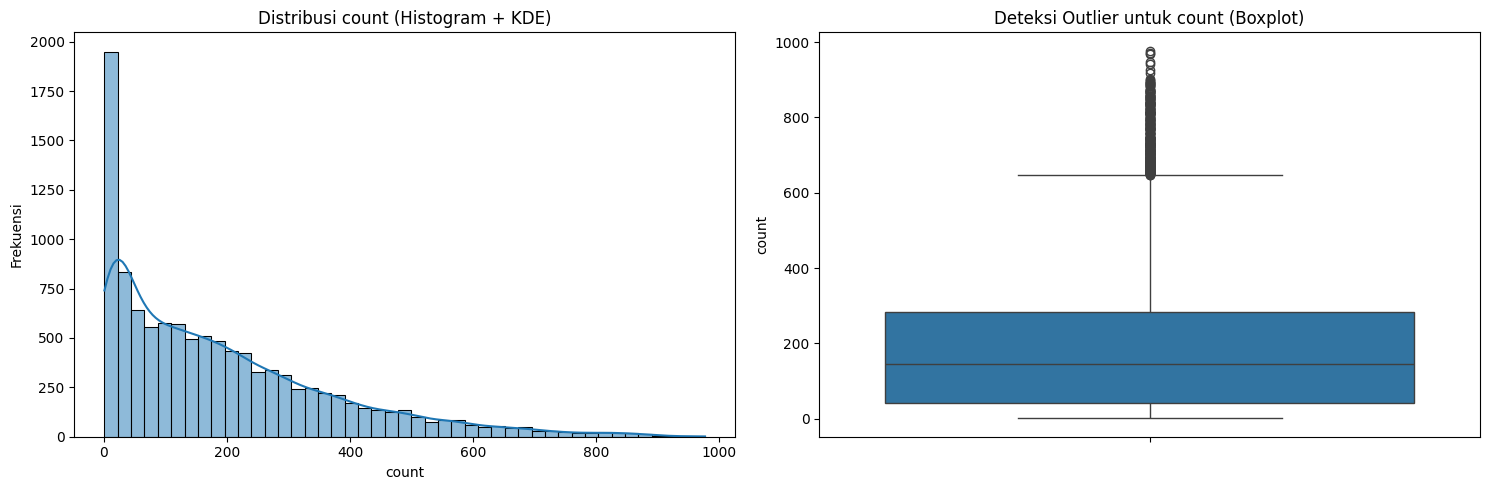


### Analisis Univariat untuk Kolom Kategorikal ###


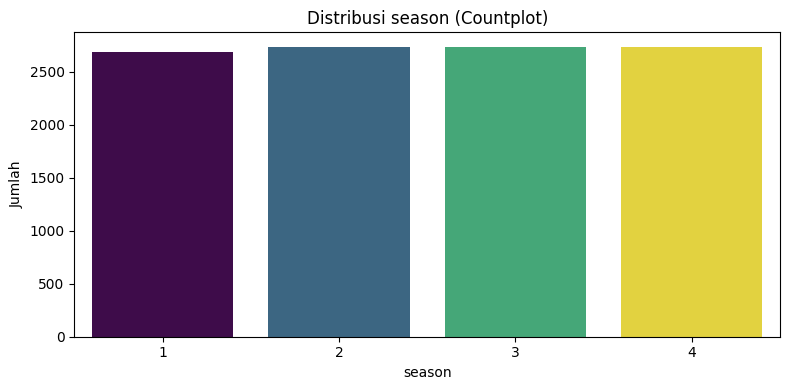

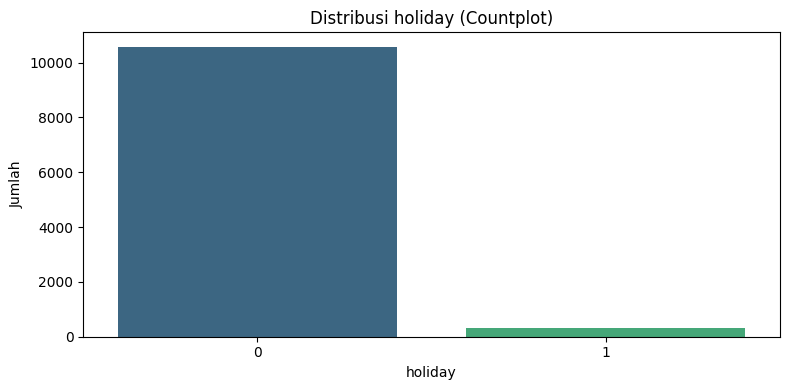

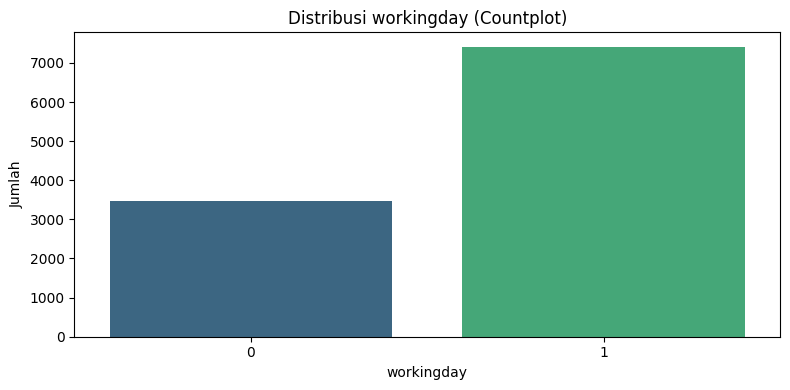

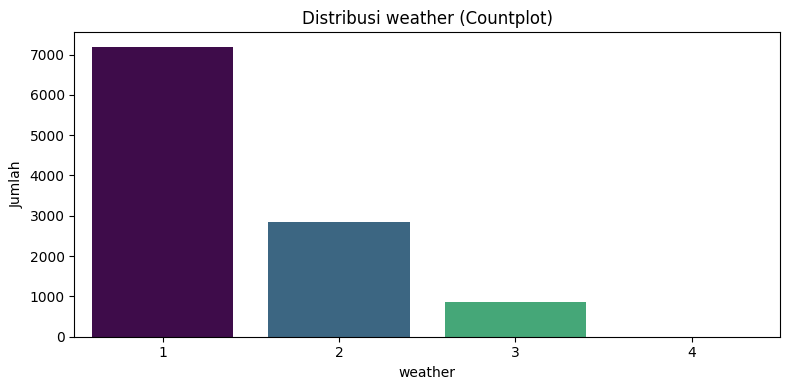

In [12]:
kolom_numerik_eda = ['temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']
kolom_kategorikal_eda = ['season', 'holiday', 'workingday', 'weather']

print("### Analisis Univariat untuk Kolom Numerik ###")
for kolom in kolom_numerik_eda:
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 2, 1)
    sns.histplot(df[kolom], kde=True)
    plt.title(f'Distribusi {kolom} (Histogram + KDE)')
    plt.xlabel(kolom)
    plt.ylabel('Frekuensi')

    plt.subplot(1, 2, 2)
    sns.boxplot(y=df[kolom])
    plt.title(f'Deteksi Outlier untuk {kolom} (Boxplot)')
    plt.ylabel(kolom)

    plt.tight_layout()
    plt.show()

print("\n### Analisis Univariat untuk Kolom Kategorikal ###")
for kolom in kolom_kategorikal_eda:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=df[kolom], order=sorted(df[kolom].unique()), hue=df[kolom],
                  palette='viridis', legend=False)
    plt.title(f'Distribusi {kolom} (Countplot)')
    plt.xlabel(kolom)
    plt.ylabel('Jumlah')
    plt.tight_layout()
    plt.show()

### Ringkasan Analisis Univariat
* **`count`, `casual`, `registered`:** histogram condong ke kanan dan boxplot menunjukkan banyak titik di atas batas atas. Nilai tinggi ini adalah **jam sibuk yang valid**, bukan kesalahan data.
* **`windspeed`:** beberapa nilai tinggi terdeteksi sebagai outlier. Nilai ini dianggap valid (angin kencang) dan ditangani dengan *winsorizing* pada tahap preprocessing.
* **`temp` dan `atemp`:** sebaran relatif simetris dan mirip satu sama lain.
* **`humidity`:** sebaran cenderung condong ke kiri (banyak hari lembap).
* **Kategorikal:** `season` relatif seimbang, sedangkan `holiday` dan `weather` tidak seimbang (mayoritas bukan libur dan cuaca cerah).

## **Ekstraksi Informasi Waktu (Fokus Utama Latihan)**

Kolom `datetime` diubah menjadi tipe waktu, lalu diekstrak menjadi **jam, hari dalam seminggu, tanggal, bulan, dan tahun**. Ekstraksi ini dilakukan sebelum analisis bivariat agar pola waktu bisa divisualisasikan.

In [13]:
df['datetime'] = pd.to_datetime(df['datetime'])

df['hour'] = df['datetime'].dt.hour
df['day'] = df['datetime'].dt.day
df['dayofweek'] = df['datetime'].dt.dayofweek   # 0 = Senin ... 6 = Minggu
df['month'] = df['datetime'].dt.month
df['year'] = df['datetime'].dt.year

print("Rentang waktu data:", df['datetime'].min(), "s.d.", df['datetime'].max())
display(df[['datetime', 'hour', 'day', 'dayofweek', 'month', 'year', 'season', 'count']].head())

Rentang waktu data: 2011-01-01 00:00:00 s.d. 2012-12-19 23:00:00


,datetime,hour,day,dayofweek,month,year,season,count
0,2011-01-01 00:00:00,0,1,5,1,2011,1,16
1,2011-01-01 01:00:00,1,1,5,1,2011,1,40
2,2011-01-01 02:00:00,2,1,5,1,2011,1,32
3,2011-01-01 03:00:00,3,1,5,1,2011,1,13
4,2011-01-01 04:00:00,4,1,5,1,2011,1,1


## **Analisis Bivariat & Multivariat (Bivariate & Multivariate Analysis)**

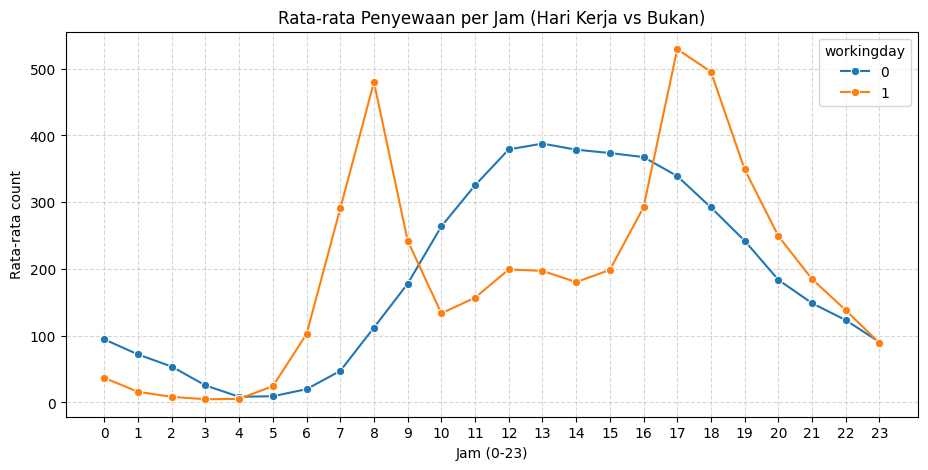

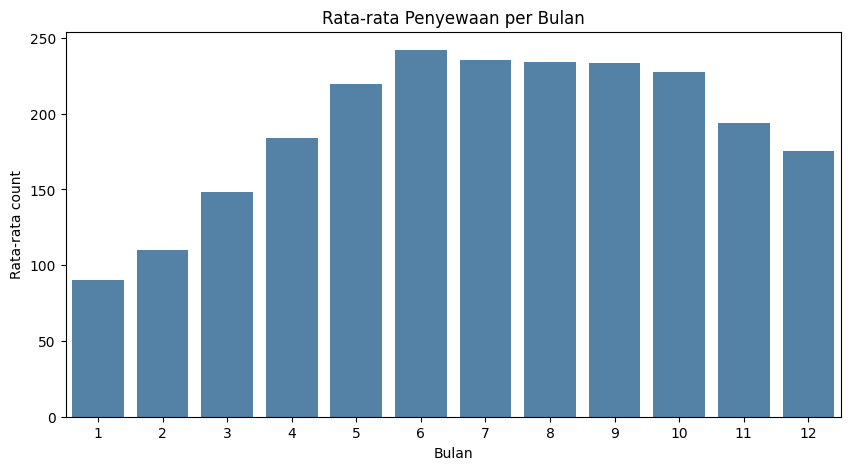

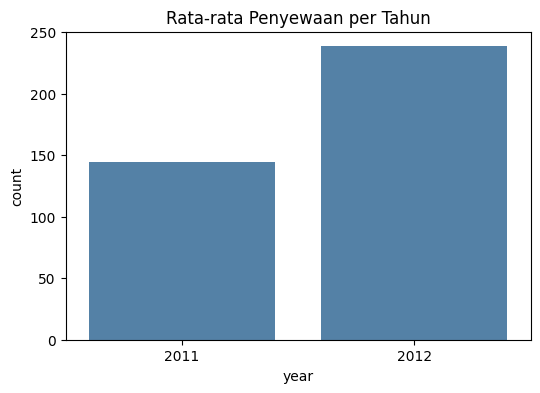

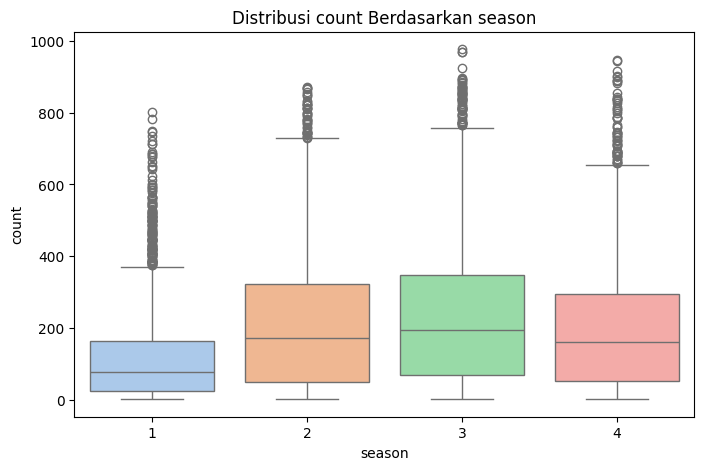

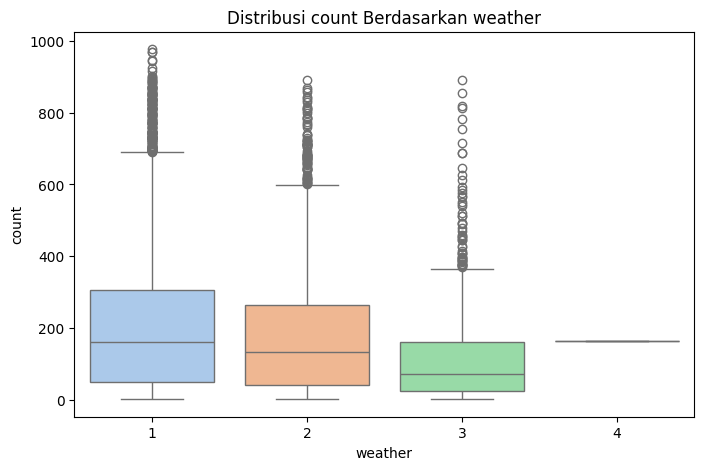

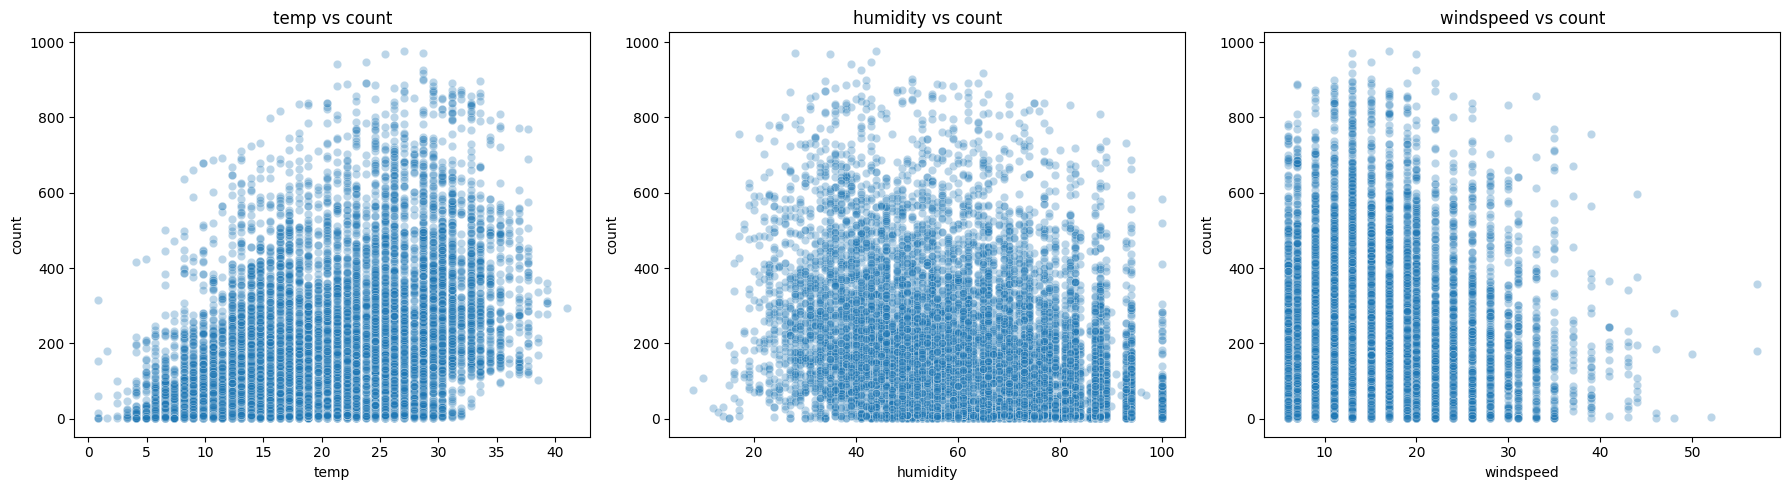

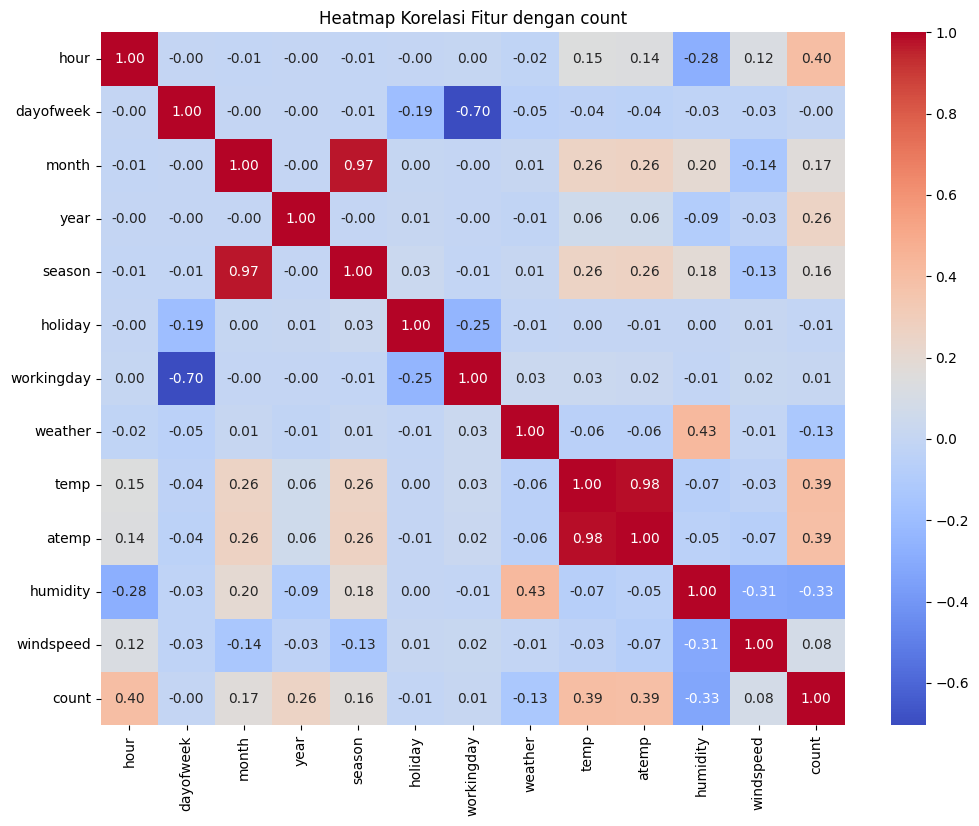

In [14]:
# 1. Rata-rata penyewaan per jam: hari kerja vs bukan hari kerja
plt.figure(figsize=(11, 5))
sns.lineplot(data=df, x='hour', y='count', hue='workingday', estimator='mean', errorbar=None, marker='o')
plt.title('Rata-rata Penyewaan per Jam (Hari Kerja vs Bukan)')
plt.xlabel('Jam (0-23)')
plt.ylabel('Rata-rata count')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Rata-rata penyewaan per bulan
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='month', y='count', errorbar=None, color='steelblue')
plt.title('Rata-rata Penyewaan per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Rata-rata count')
plt.show()

# 3. Rata-rata penyewaan per tahun
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='year', y='count', errorbar=None, color='steelblue')
plt.title('Rata-rata Penyewaan per Tahun')
plt.show()

# 4. Boxplot count berdasarkan season dan weather
for kat in ['season', 'weather']:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x=kat, y='count', hue=kat, palette='pastel', legend=False)
    plt.title(f'Distribusi count Berdasarkan {kat}')
    plt.show()

# 5. Scatter plot cuaca vs count
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, kolom in zip(axes, ['temp', 'humidity', 'windspeed']):
    sns.scatterplot(data=df, x=kolom, y='count', alpha=0.3, ax=ax)
    ax.set_title(f'{kolom} vs count')
plt.tight_layout()
plt.show()

# 6. Heatmap korelasi
kolom_korelasi = ['hour', 'dayofweek', 'month', 'year', 'season', 'holiday', 'workingday',
                  'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'count']
plt.figure(figsize=(12, 9))
sns.heatmap(df[kolom_korelasi].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi Fitur dengan count')
plt.show()

### Ringkasan Analisis Bivariat & Multivariat
1. **Pola jam:** pada **hari kerja** terlihat dua puncak (pagi sekitar jam berangkat kerja dan sore sekitar jam pulang), sedangkan pada **bukan hari kerja** puncaknya tunggal di siang hari. Jadi `hour` adalah salah satu prediktor terkuat, tetapi hubungannya **tidak linear** (berbentuk gelombang).
2. **Pola bulan/musim:** penyewaan cenderung lebih tinggi pada bulan-bulan hangat dan lebih rendah pada bulan dingin.
3. **Pola tahun:** rata-rata penyewaan tahun kedua lebih tinggi dari tahun pertama, menunjukkan tren pertumbuhan penggunaan layanan.
4. **Cuaca:** semakin buruk kategori `weather`, semakin rendah penyewaan. `temp` berkorelasi positif dengan `count`, sedangkan `humidity` cenderung negatif.
5. **Multikolinearitas:** `temp` dan `atemp` berkorelasi sangat tinggi (mendekati 1), sehingga memuat informasi yang hampir sama. Hal ini diperhatikan pada tahap feature engineering.
6. Korelasi linear `hour` terhadap `count` tampak lemah, padahal pengaruhnya besar. Ini terjadi karena pola jam bersifat melingkar/gelombang, bukan garis lurus. Maka `hour` perlu direpresentasikan secara **siklik**.

# **Preprocessing & Feature Engineering**

Alur: **Cek Missing Value → Hapus Kolom Leakage → Penanganan Outlier → Feature Engineering Waktu → Encoding → Pisah X/y → Train/Test Split → Scaling → Verifikasi**

Catatan: split dilakukan **sebelum scaling** untuk mencegah *data leakage*.

## **Langkah 1 — Menangani Nilai Hilang**

In [15]:
print("--- Missing Value ---")
display(df.isnull().sum())

# Jika ada missing value numerik, isi dengan median (pada dataset ini umumnya tidak ada)
for kolom in df.select_dtypes(include='number').columns:
    if df[kolom].isnull().any():
        df[kolom] = df[kolom].fillna(df[kolom].median())

print("Total missing value setelah penanganan:", df.isnull().sum().sum())

--- Missing Value ---


,0
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0
casual,0


Total missing value setelah penanganan: 0


Nilai kosong dan nilai kotor sudah ditangani pada bagian **Klasifikasi Data: Kosong, Kotor, dan Bersih**. Kode di atas hanya berfungsi sebagai pengecekan ulang.

## **Langkah 2 — Menghapus Kolom Penyebab Data Leakage**

`casual` dan `registered` dibuang karena `count = casual + registered`. Kolom `datetime` asli juga dibuang karena informasinya sudah diekstrak menjadi `hour`, `dayofweek`, `month`, dan `year`.

Kolom `day` (tanggal dalam bulan) juga dibuang. Pada data Kaggle, `train.csv` hanya berisi tanggal 1-19 setiap bulan, sedangkan tanggal 20 dst. berada di data uji, sehingga `day` tidak bisa digeneralisasi dan tidak memiliki makna prediktif yang berguna.

In [16]:
df_model = df.drop(columns=['casual', 'registered', 'datetime', 'day']).copy()
print("Kolom tersisa:", df_model.columns.tolist())

Kolom tersisa: ['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'count', 'hour', 'dayofweek', 'month', 'year']


## **Langkah 3 — Penanganan Outlier pada `count`**

Distribusi `count` bersifat *right-skewed* dan nilai tingginya valid (jam sibuk), sehingga **tidak dihapus**. Seperti pada panduan penanganan outlier, **transformasi logaritmik (`log1p`)** dipilih untuk mengurangi kemiringan tanpa membuang observasi.

Deteksi dilakukan dengan **boxplot dan IQR**.

========== DETEKSI OUTLIER DENGAN IQR (count) ==========
Q1             : 42.0
Q3             : 284.0
IQR            : 242.0
Batas bawah    : -321.0
Batas atas     : 647.0
Jumlah outlier : 300 (2.76%)

========== PERBANDINGAN SKEWNESS ==========
Skewness sebelum log : 1.2421
Skewness sesudah log : -0.8514


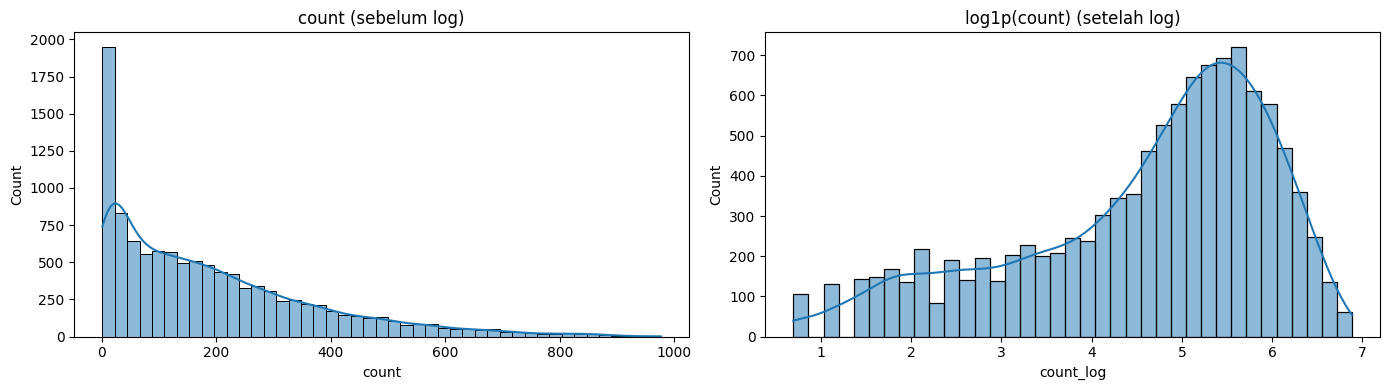


Batas persentil 99 windspeed: 35.001


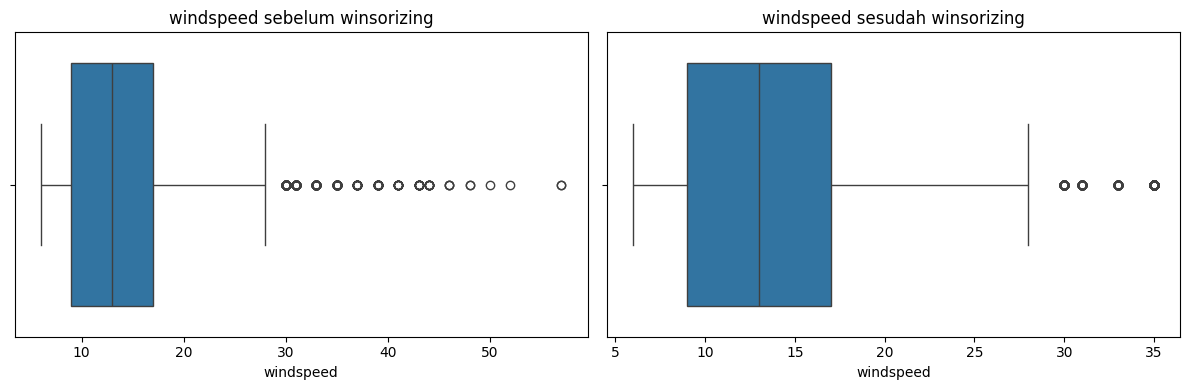

In [17]:
import numpy as np

target_col = 'count'

Q1 = df_model[target_col].quantile(0.25)
Q3 = df_model[target_col].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
outlier_iqr = df_model[(df_model[target_col] < batas_bawah) | (df_model[target_col] > batas_atas)]

print("========== DETEKSI OUTLIER DENGAN IQR (count) ==========")
print("Q1             :", Q1)
print("Q3             :", Q3)
print("IQR            :", IQR)
print("Batas bawah    :", batas_bawah)
print("Batas atas     :", batas_atas)
print("Jumlah outlier :", len(outlier_iqr), f"({len(outlier_iqr)/len(df_model)*100:.2f}%)")

# Transformasi logaritmik
df_model['count_log'] = np.log1p(df_model[target_col])

print("\n========== PERBANDINGAN SKEWNESS ==========")
print("Skewness sebelum log :", round(df_model[target_col].skew(), 4))
print("Skewness sesudah log :", round(df_model['count_log'].skew(), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_model[target_col], kde=True, ax=axes[0])
axes[0].set_title('count (sebelum log)')
sns.histplot(df_model['count_log'], kde=True, ax=axes[1])
axes[1].set_title('log1p(count) (setelah log)')
plt.tight_layout()
plt.show()

# Winsorizing ringan untuk windspeed (nilai ekstrem dibatasi pada persentil 99)
batas_wind = df_model['windspeed'].quantile(0.99)
print("\nBatas persentil 99 windspeed:", round(batas_wind, 3))
wind_sebelum = df_model['windspeed'].copy()
df_model['windspeed'] = df_model['windspeed'].clip(upper=batas_wind)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=wind_sebelum, ax=axes[0])
axes[0].set_title('windspeed sebelum winsorizing')
sns.boxplot(x=df_model['windspeed'], ax=axes[1])
axes[1].set_title('windspeed sesudah winsorizing')
plt.tight_layout()
plt.show()

Skewness `count` turun setelah transformasi log. Pada `windspeed`, nilai ekstrem dibatasi pada persentil ke-99 (*winsorizing*) agar tidak terlalu memengaruhi regresi, tanpa menghapus baris.

## **Langkah 4 — Feature Engineering Waktu**

1. **Encoding siklik untuk `hour` dan `month`.** Jam 23 dan jam 0 sebenarnya bersebelahan, tetapi bila dipakai sebagai angka biasa jaraknya tampak 23. Dengan transformasi sinus-kosinus, sifat melingkar ini terjaga:

   `hour_sin = sin(2π · hour / 24)`, `hour_cos = cos(2π · hour / 24)` (begitu juga untuk `month` dengan periode 12).
2. **Membuang `atemp`** karena berkorelasi sangat tinggi dengan `temp` (multikolinearitas), yang membuat koefisien regresi tidak stabil.
3. **Mengubah `dayofweek` menjadi indikator akhir pekan (`is_weekend`).**

Korelasi temp-atemp: 0.985


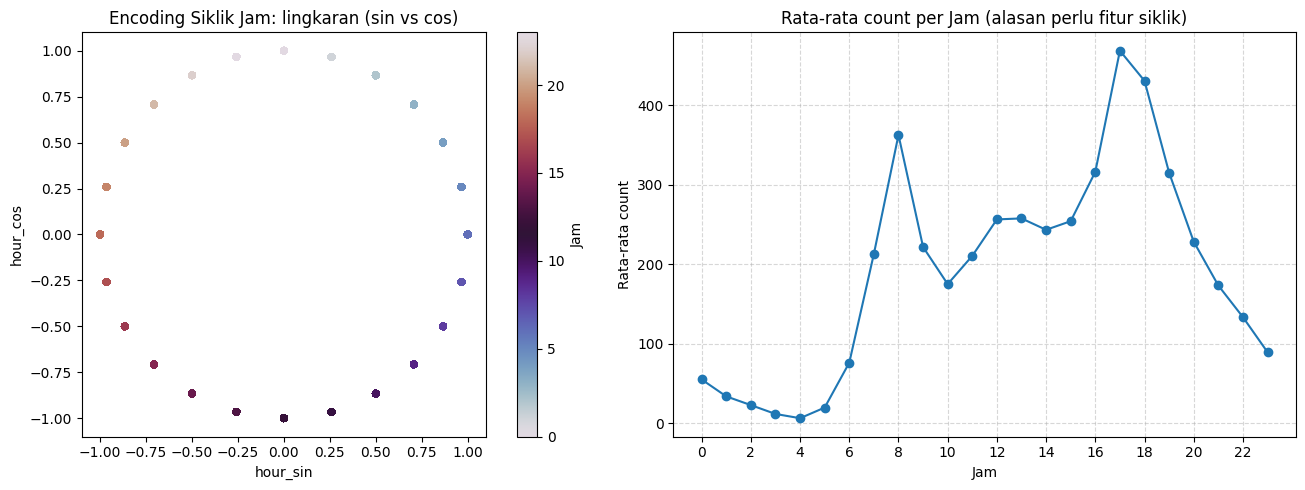

Kolom setelah feature engineering: ['season', 'holiday', 'workingday', 'weather', 'temp', 'humidity', 'windspeed', 'count', 'year', 'count_log', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_weekend']


,season,holiday,workingday,weather,temp,humidity,windspeed,count,year,count_log,hour_sin,hour_cos,month_sin,month_cos,is_weekend
0,1,0,0,1,9.84,81.0,12.998,16,2011,2.833213,0.000000,1.000000,0.5,0.866025,1
1,1,0,0,1,9.02,80.0,12.998,40,2011,3.713572,0.258819,0.965926,0.5,0.866025,1
2,1,0,0,1,9.02,80.0,12.998,32,2011,3.496508,0.500000,0.866025,0.5,0.866025,1
3,1,0,0,1,9.84,75.0,12.998,13,2011,2.639057,0.707107,0.707107,0.5,0.866025,1
4,1,0,0,1,9.84,75.0,12.998,1,2011,0.693147,0.866025,0.500000,0.5,0.866025,1


In [18]:
df_model['hour_sin'] = np.sin(2 * np.pi * df_model['hour'] / 24)
df_model['hour_cos'] = np.cos(2 * np.pi * df_model['hour'] / 24)
df_model['month_sin'] = np.sin(2 * np.pi * df_model['month'] / 12)
df_model['month_cos'] = np.cos(2 * np.pi * df_model['month'] / 12)
df_model['is_weekend'] = (df_model['dayofweek'] >= 5).astype(int)

print("Korelasi temp-atemp:", round(df_model['temp'].corr(df_model['atemp']), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc1 = axes[0].scatter(df_model['hour_sin'], df_model['hour_cos'], c=df_model['hour'], cmap='twilight', s=20)
axes[0].set_title('Encoding Siklik Jam: lingkaran (sin vs cos)')
axes[0].set_xlabel('hour_sin')
axes[0].set_ylabel('hour_cos')
axes[0].set_aspect('equal')
plt.colorbar(sc1, ax=axes[0], label='Jam')

rata_jam = df_model.groupby('hour')['count'].mean()
axes[1].plot(rata_jam.index, rata_jam.values, marker='o')
axes[1].set_title('Rata-rata count per Jam (alasan perlu fitur siklik)')
axes[1].set_xlabel('Jam')
axes[1].set_ylabel('Rata-rata count')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

df_model = df_model.drop(columns=['hour', 'month', 'dayofweek', 'atemp'])
print("Kolom setelah feature engineering:", df_model.columns.tolist())
display(df_model.head())

## **Langkah 5 — Memisahkan Fitur (X) dan Label (y)**

* **X** → seluruh fitur.
* **y** → `count_log` (target model setelah transformasi log).
* **y_original** → `count` asli, disimpan untuk evaluasi pada skala jumlah penyewaan sebenarnya.

In [19]:
X = df_model.drop(columns=['count', 'count_log']).copy()
y = df_model['count_log'].copy()
y_original = df_model['count'].copy()

print("Dimensi X:", X.shape)
print("Dimensi y:", y.shape)
print("\nKolom fitur:", X.columns.tolist())

Dimensi X: (10886, 13)
Dimensi y: (10886,)

Kolom fitur: ['season', 'holiday', 'workingday', 'weather', 'temp', 'humidity', 'windspeed', 'year', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_weekend']


## **Langkah 6 — Encoding Data Kategorikal**

`season` dan `weather` bertipe angka tetapi **nominal** (tidak punya jarak/urutan numerik yang bermakna), jadi diubah dengan **one-hot encoding**. `drop_first=True` dipakai untuk menghindari *dummy variable trap* (multikolinearitas sempurna) pada regresi linear.

`holiday`, `workingday`, `year`, dan `is_weekend` sudah berupa indikator biner/ordinal sehingga dibiarkan.

Dimensi X setelah one-hot encoding: (10886, 17)


,holiday,workingday,temp,humidity,windspeed,year,hour_sin,hour_cos,month_sin,month_cos,is_weekend,season_2,season_3,season_4,weather_2,weather_3,weather_4
0,0,0,9.84,81.0,12.998,2011,0.000000,1.000000,0.5,0.866025,1,0,0,0,0,0,0
1,0,0,9.02,80.0,12.998,2011,0.258819,0.965926,0.5,0.866025,1,0,0,0,0,0,0
2,0,0,9.02,80.0,12.998,2011,0.500000,0.866025,0.5,0.866025,1,0,0,0,0,0,0
3,0,0,9.84,75.0,12.998,2011,0.707107,0.707107,0.5,0.866025,1,0,0,0,0,0,0
4,0,0,9.84,75.0,12.998,2011,0.866025,0.500000,0.5,0.866025,1,0,0,0,0,0,0


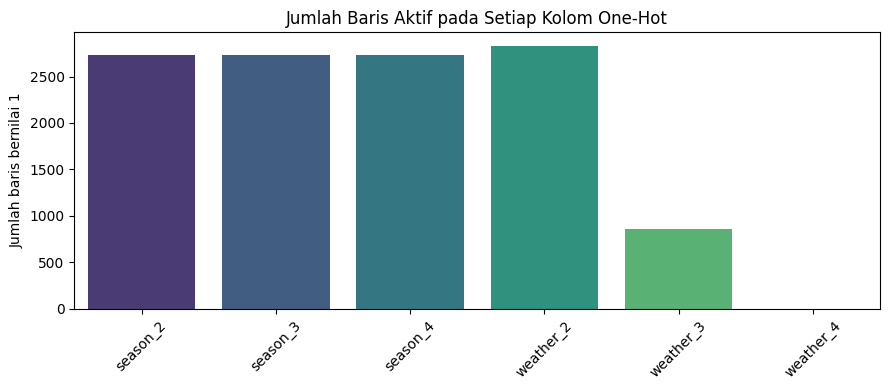

In [20]:
X = pd.get_dummies(X, columns=['season', 'weather'], drop_first=True, dtype=int)

print("Dimensi X setelah one-hot encoding:", X.shape)
display(X.head())

dummy_cols = [c for c in X.columns if c.startswith('season_') or c.startswith('weather_')]
plt.figure(figsize=(9, 4))
sns.barplot(x=dummy_cols, y=X[dummy_cols].sum().values, hue=dummy_cols, palette='viridis', legend=False)
plt.title('Jumlah Baris Aktif pada Setiap Kolom One-Hot')
plt.ylabel('Jumlah baris bernilai 1')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## **Langkah 7 — Membagi Data Latih dan Data Uji (Sebelum Scaling)**

* **70% data latih**, **30% data uji**
* `random_state=42` agar hasil dapat direproduksi.

> **Catatan:** data ini berbasis waktu. Pembagian acak dipakai agar konsisten dengan modul praktikum. Untuk skenario prediksi masa depan yang sebenarnya, pembagian secara kronologis lebih tepat. Hal ini dapat disebut sebagai keterbatasan.

X_train: (7620, 17)
X_test : (3266, 17)
y_train: (7620,)
y_test : (3266,)


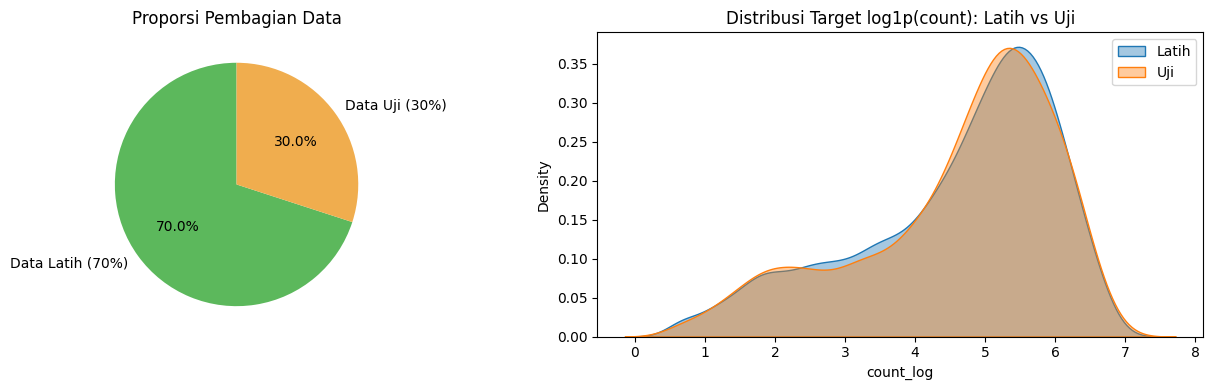

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, y_original_train, y_original_test = train_test_split(
    X, y, y_original, test_size=0.3, random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].pie([len(X_train), len(X_test)], labels=['Data Latih (70%)', 'Data Uji (30%)'],
            autopct='%1.1f%%', colors=['#5cb85c', '#f0ad4e'], startangle=90)
axes[0].set_title('Proporsi Pembagian Data')

sns.kdeplot(y_train, ax=axes[1], label='Latih', fill=True, alpha=0.4)
sns.kdeplot(y_test, ax=axes[1], label='Uji', fill=True, alpha=0.4)
axes[1].set_title('Distribusi Target log1p(count): Latih vs Uji')
axes[1].legend()
plt.tight_layout()
plt.show()

## **Langkah 8 — Penskalaan Fitur dengan StandardScaler**

Hanya fitur **kontinu** (`temp`, `humidity`, `windspeed`) yang di-scale. Fitur biner/one-hot dan fitur siklik (sin/cos sudah berada di rentang -1 sampai 1) tidak perlu distandardisasi.

* `fit_transform()` hanya pada **data latih**.
* `transform()` pada **data uji**, sehingga tidak ada data leakage.

Kolom yang di-scale: ['temp', 'humidity', 'windspeed']


,holiday,workingday,temp,humidity,windspeed,year,hour_sin,hour_cos,month_sin,month_cos,is_weekend,season_2,season_3,season_4,weather_2,weather_3,weather_4
613,0,1,-1.435689,-1.573886,3.175371,2011,-0.965926,-2.588190e-01,0.866025,5.000000e-01,0,0,0,0,0,0,0
4030,0,0,0.241269,0.315306,-0.204423,2011,-0.258819,9.659258e-01,-1.000000,-1.836970e-16,1,0,1,0,0,0,0
3582,0,1,0.765318,1.102469,-0.204423,2011,0.866025,5.000000e-01,-0.866025,-5.000000e-01,0,0,1,0,0,0,0
10101,0,1,-1.435689,0.367784,-0.818837,2012,1.000000,6.123234e-17,-0.500000,8.660254e-01,0,0,0,1,0,0,0
1430,0,1,-0.911640,0.997514,2.407611,2011,0.258819,-9.659258e-01,0.866025,-5.000000e-01,0,1,0,0,0,1,0


,temp,humidity,windspeed
count,7620.000,7620.000,7620.000
mean,-0.000,-0.000,0.000
std,1.000,1.000,1.000
min,-2.484,-2.728,-1.279
25%,-0.807,-0.787,-0.819
50%,0.032,0.000,-0.204
75%,0.765,0.788,0.410
max,2.652,1.995,3.175


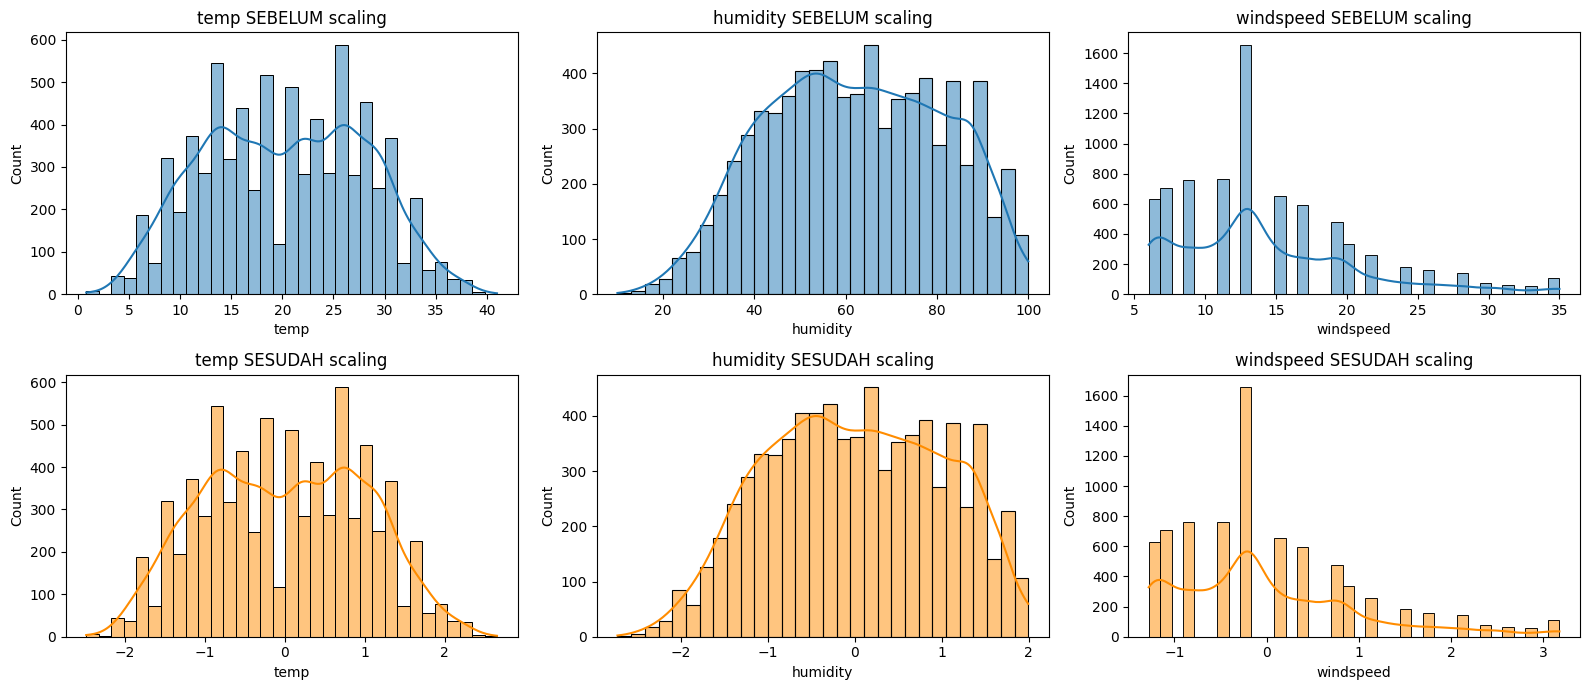

In [22]:
from sklearn.preprocessing import StandardScaler

kolom_scaling = ['temp', 'humidity', 'windspeed']
print("Kolom yang di-scale:", kolom_scaling)

X_train_sebelum = X_train[kolom_scaling].copy()
sc = StandardScaler()
X_train[kolom_scaling] = sc.fit_transform(X_train[kolom_scaling])
X_test[kolom_scaling] = sc.transform(X_test[kolom_scaling])

display(X_train.head())
display(X_train[kolom_scaling].describe().round(3))

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for i, kolom in enumerate(kolom_scaling):
    sns.histplot(X_train_sebelum[kolom], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f'{kolom} SEBELUM scaling')
    sns.histplot(X_train[kolom], kde=True, ax=axes[1, i], color='darkorange')
    axes[1, i].set_title(f'{kolom} SESUDAH scaling')
plt.tight_layout()
plt.show()

## **Langkah 9 — Verifikasi Hasil Preprocessing**

========== VERIFIKASI PREPROCESSING ==========

1. Missing value X_train: 0
   Missing value X_test : 0

2. Tipe data X_train:
holiday         int64
workingday      int64
temp          float64
humidity      float64
windspeed     float64
year            int32
hour_sin      float64
hour_cos      float64
month_sin     float64
month_cos     float64
is_weekend      int64
season_2        int64
season_3        int64
season_4        int64
weather_2       int64
weather_3       int64
weather_4       int64
dtype: object

3. Ukuran data:
X_train: (7620, 17) | X_test: (3266, 17)
y_train: (7620,) | y_test: (3266,)

4. Statistik fitur ter-scale (mean ~0, std ~1):


,temp,humidity,windspeed
count,7620.000,7620.000,7620.000
mean,-0.000,-0.000,0.000
std,1.000,1.000,1.000
min,-2.484,-2.728,-1.279
25%,-0.807,-0.787,-0.819
50%,0.032,0.000,-0.204
75%,0.765,0.788,0.410
max,2.652,1.995,3.175


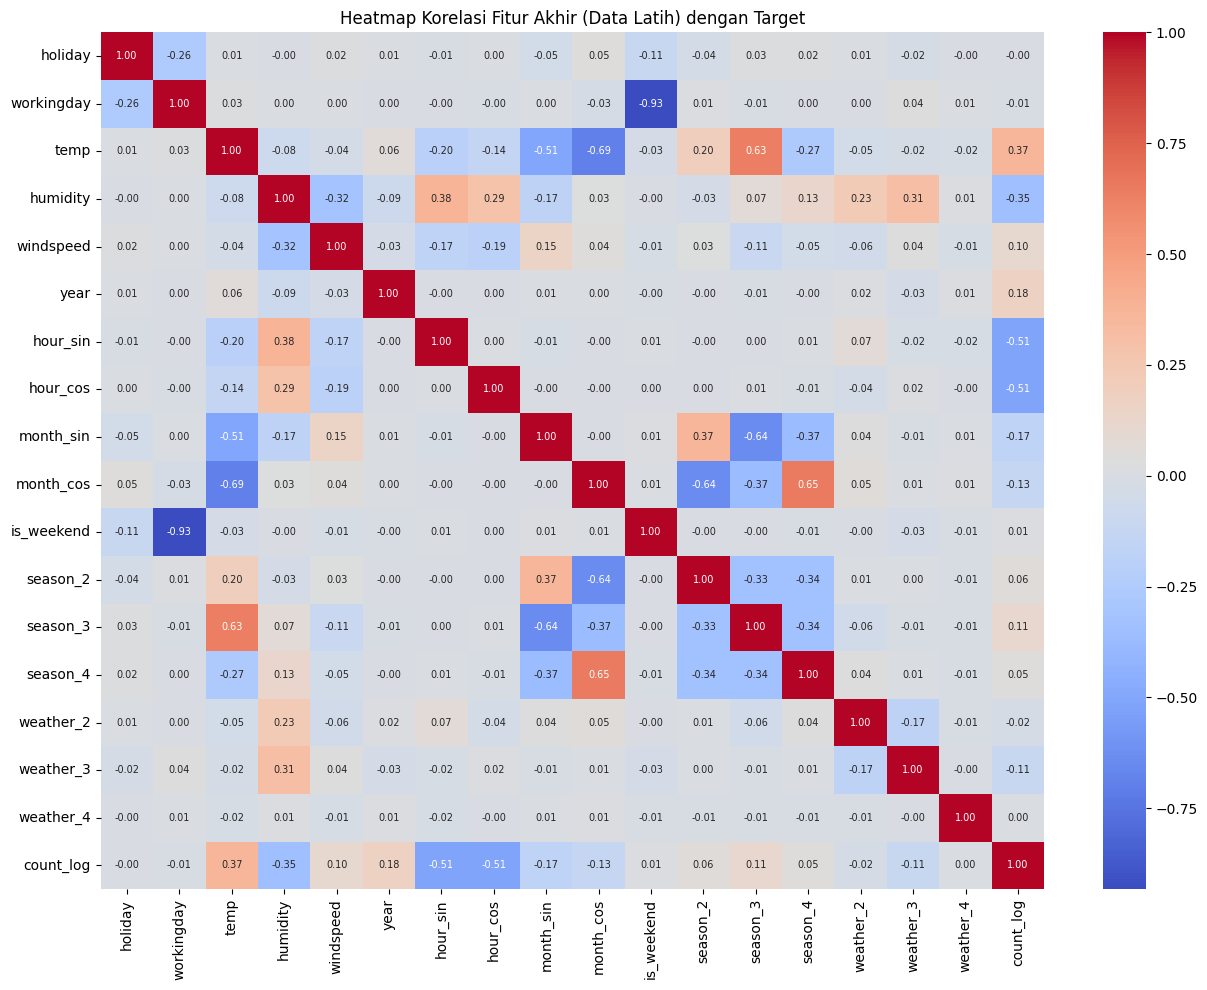

In [23]:
print("========== VERIFIKASI PREPROCESSING ==========")
print("\n1. Missing value X_train:", X_train.isnull().sum().sum())
print("   Missing value X_test :", X_test.isnull().sum().sum())

print("\n2. Tipe data X_train:")
print(X_train.dtypes)

print("\n3. Ukuran data:")
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

print("\n4. Statistik fitur ter-scale (mean ~0, std ~1):")
display(X_train[kolom_scaling].describe().round(3))

# 5. Korelasi fitur akhir dengan target
data_korelasi = X_train.copy()
data_korelasi['count_log'] = y_train
plt.figure(figsize=(13, 10))
sns.heatmap(data_korelasi.corr(), annot=True, fmt=".2f", cmap='coolwarm', annot_kws={'size': 7})
plt.title('Heatmap Korelasi Fitur Akhir (Data Latih) dengan Target')
plt.tight_layout()
plt.show()

## **Kesimpulan Preprocessing**

**Alur:** Data Bersih → Hapus Leakage → Outlier (log) → Feature Engineering Waktu → X/y → One-Hot → Split → Scaling → Verifikasi

* Data dikelompokkan menjadi **kosong, kotor, dan bersih**, lalu dibersihkan (duplikat dihapus, nilai tidak valid diimputasi median) sehingga data akhir berstatus bersih.
* `casual` dan `registered` dibuang untuk mencegah data leakage.
* `datetime` diekstrak menjadi `hour`, `month`, `year`, dan `dayofweek`, lalu `hour` dan `month` diubah menjadi fitur siklik (sin/cos).
* Target `count` ditransformasi `log1p` untuk menangani skewness.
* `season` dan `weather` di-*one-hot encode*; `atemp` dibuang karena multikolinearitas dengan `temp`.
* Data dibagi 70:30 dengan `random_state=42`, scaling hanya di-*fit* pada data latih.

# **Pemodelan Regresi Linear**

Model: **regresi linear berganda**

**y = b₀ + b₁x₁ + b₂x₂ + ... + bₙxₙ**

dengan `y` = prediksi `log1p(count)`, `b₀` = intercept, `b₁...bₙ` = koefisien fitur.

## **Langkah 1 — Menyiapkan Pustaka dan Data**

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Data latih :", X_train.shape)
print("Data uji   :", X_test.shape)

Data latih : (7620, 17)
Data uji   : (3266, 17)


## **Langkah 2 — Membuat dan Melatih Model**

In [25]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model regresi linear berhasil dilatih.")

Model regresi linear berhasil dilatih.


## **Langkah 3 — Koefisien dan Intercept**

Karena target berupa `log1p(count)`, koefisien dibaca sebagai **perubahan relatif (persentase kira-kira)** pada jumlah penyewaan. Misalnya, koefisien 0,1 pada fitur biner berarti jumlah penyewaan naik sekitar 10% (dengan fitur lain tetap).

Untuk fitur yang sudah distandardisasi (`temp`, `humidity`, `windspeed`), koefisien menunjukkan efek perubahan **satu standar deviasi**.

Intercept: -995.5486

Koefisien Regresi:


,Fitur,Koefisien,Perubahan_relatif_%
13,season_4,0.576038,77.90
5,year,0.497116,64.40
12,season_3,0.202637,22.46
11,season_2,0.172438,18.82
10,is_weekend,0.052439,5.38
2,temp,0.050107,5.14
3,humidity,0.010594,1.07
1,workingday,-0.004861,-0.48
0,holiday,-0.047578,-4.65
4,windspeed,-0.053326,-5.19


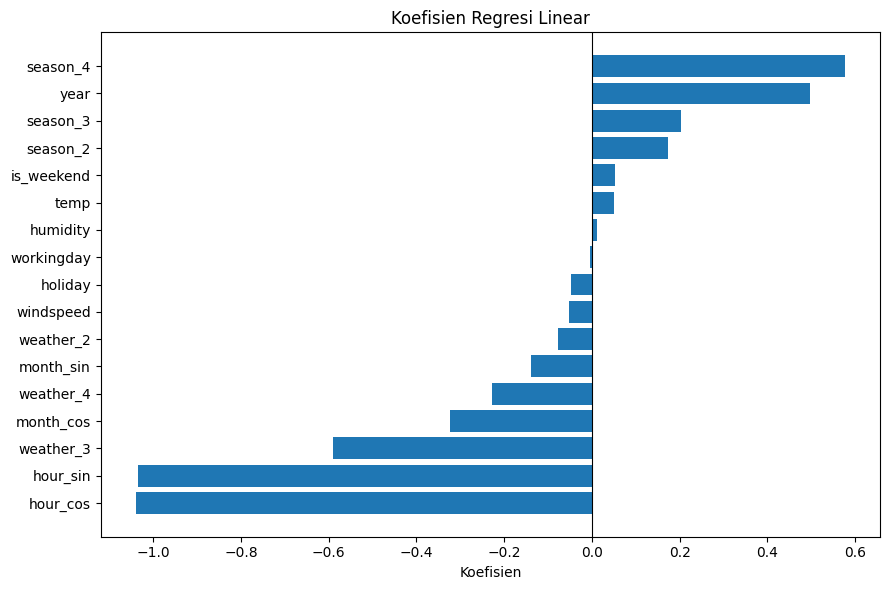

In [26]:
print("Intercept:", round(model.intercept_, 4))

koefisien = pd.DataFrame({
    "Fitur": X_train.columns,
    "Koefisien": model.coef_,
    "Perubahan_relatif_%": (np.expm1(model.coef_) * 100).round(2)
}).sort_values("Koefisien", ascending=False)

print("\nKoefisien Regresi:")
display(koefisien)

plt.figure(figsize=(9, 6))
plt.barh(koefisien['Fitur'], koefisien['Koefisien'])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Koefisien Regresi Linear')
plt.xlabel('Koefisien')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## **Langkah 4 — Prediksi dan Evaluasi Model**

Prediksi dari model berskala log, kemudian dikembalikan ke skala asli dengan `expm1()`. Metrik dihitung pada **data uji**:

1. **MSE** — rata-rata kuadrat kesalahan.
2. **RMSE** — akar MSE, satuannya sama dengan `count` (jumlah penyewaan).
3. **R²** — proporsi variasi target yang dijelaskan model.
4. **RMSLE** — metrik resmi kompetisi Kaggle Bike Sharing Demand (RMSE pada skala log), cocok karena `count` miring ke kanan.

In [27]:
y_pred_log = model.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_pred = np.clip(y_pred, 0, None)   # penyewaan tidak mungkin negatif

mse = mean_squared_error(y_original_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_original_test, y_pred)

# Metrik pada skala log (RMSLE)
rmsle = np.sqrt(mean_squared_error(y_test, y_pred_log))
r2_log = r2_score(y_test, y_pred_log)

# Pembanding: R2 pada data latih
r2_train_log = r2_score(y_train, model.predict(X_train))

print("========== EVALUASI MODEL (skala asli) ==========")
print("MSE  :", round(mse, 3))
print("RMSE :", round(rmse, 3))
print("R²   :", round(r2, 3))

print("\n========== EVALUASI MODEL (skala log) ==========")
print("RMSLE         :", round(rmsle, 4))
print("R² (log, uji) :", round(r2_log, 3))
print("R² (log, latih):", round(r2_train_log, 3))

========== EVALUASI MODEL (skala asli) ==========
MSE  : 22181.685
RMSE : 148.935
R²   : 0.318

========== EVALUASI MODEL (skala log) ==========
RMSLE         : 0.8611
R² (log, uji) : 0.627
R² (log, latih): 0.63


### Interpretasi Hasil Evaluasi
* **RMSE** menyatakan rata-rata kesalahan prediksi dalam satuan jumlah penyewaan per jam. Bandingkan dengan rata-rata `count` (sekitar 190) untuk menilai besarnya galat secara relatif.
* **R²** menunjukkan seberapa besar variasi `count` yang dapat dijelaskan model.
* Jika R² data latih dan data uji berdekatan, model tidak mengalami *overfitting*.
* Regresi linear cenderung **kurang cocok** untuk data ini karena pola jam, musim, dan cuaca bersifat tidak linear serta penuh interaksi. Hasil yang sedang-sedang saja adalah hal yang wajar, dan bisa dibahas sebagai keterbatasan model beserta saran perbaikan (lihat bagian kesimpulan).

> **Isi bagian ini dengan angka aktual** dari hasil sel di atas ketika dijalankan, misalnya: "RMSE sebesar ... menunjukkan ..., R² sebesar ... berarti model menjelaskan ...% variasi."

## **Langkah 5 — Analisis Residual**

**Residual = y aktual − y prediksi**

* Titik tersebar acak di sekitar garis 0 → kesalahan relatif seimbang.
* Pola melengkung → hubungan sebenarnya tidak linear.
* Sebaran melebar pada prediksi besar → indikasi heteroskedastisitas.

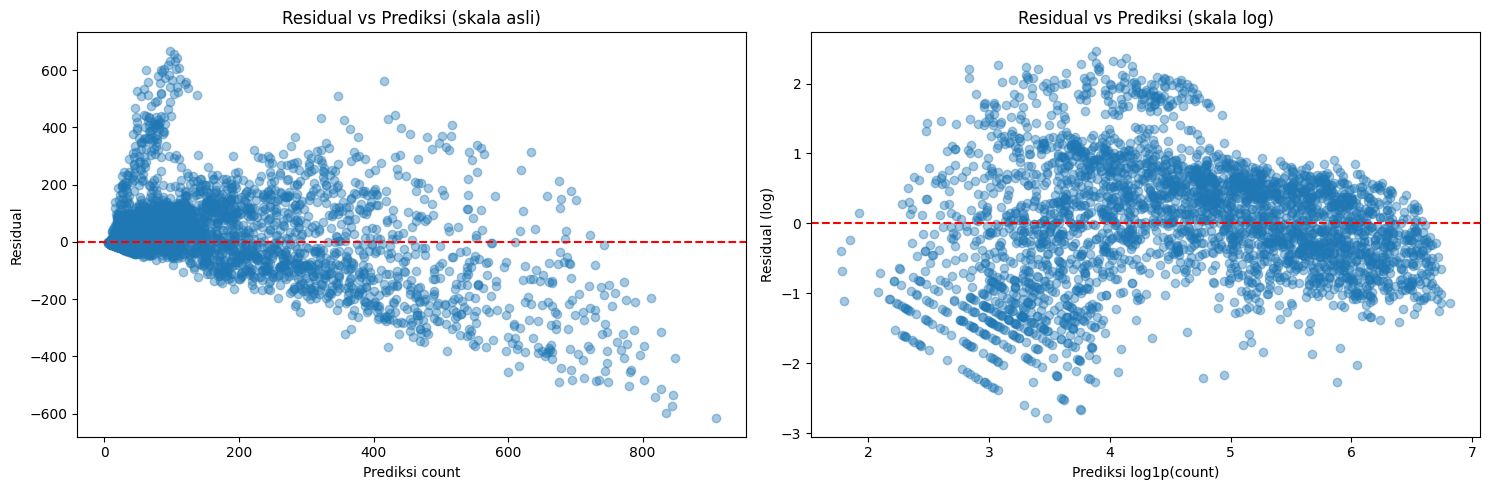

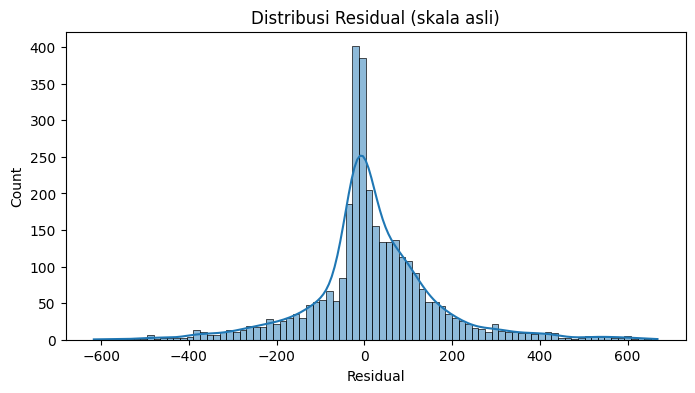

In [28]:
residual = y_original_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_pred, residual, alpha=0.4)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Prediksi count')
axes[0].set_ylabel('Residual')
axes[0].set_title('Residual vs Prediksi (skala asli)')

residual_log = y_test - y_pred_log
axes[1].scatter(y_pred_log, residual_log, alpha=0.4)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Prediksi log1p(count)')
axes[1].set_ylabel('Residual (log)')
axes[1].set_title('Residual vs Prediksi (skala log)')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(residual, kde=True)
plt.title('Distribusi Residual (skala asli)')
plt.xlabel('Residual')
plt.show()

### Interpretasi Residual
* Pada skala asli, residual cenderung **melebar** seiring naiknya nilai prediksi (heteroskedastisitas) dan terlihat pola tertentu, tanda bahwa asumsi linearitas tidak sepenuhnya terpenuhi.
* Transformasi log membantu menstabilkan varians, terlihat dari plot residual skala log yang lebih rata.
* Residual besar umumnya terjadi pada jam-jam sibuk yang sulit diprediksi oleh model linear.

## **Visualisasi Nilai Aktual vs Prediksi**

Semakin dekat titik ke garis diagonal `y = x`, semakin baik prediksinya. Nilai aktual yang digunakan adalah **`y_original_test`** (skala asli) agar sebanding dengan `y_pred`.

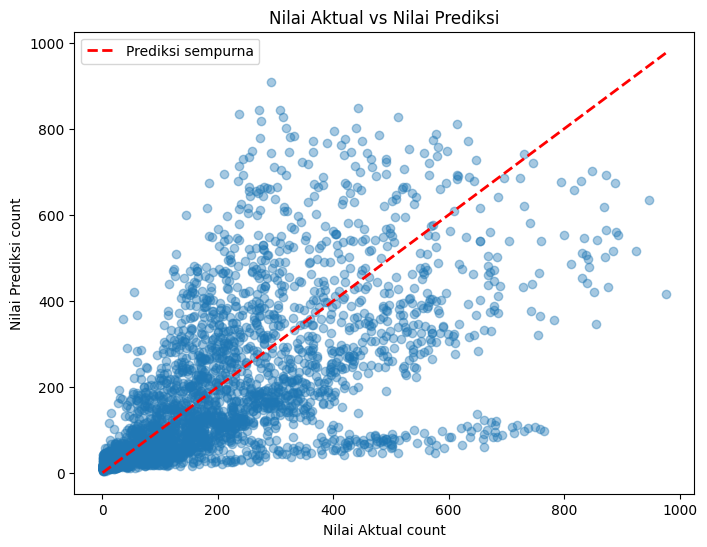

In [29]:
plt.figure(figsize=(8, 6))
plt.scatter(y_original_test, y_pred, alpha=0.4)

nilai_min = min(y_original_test.min(), y_pred.min())
nilai_max = max(y_original_test.max(), y_pred.max())
plt.plot([nilai_min, nilai_max], [nilai_min, nilai_max], 'r--', linewidth=2, label='Prediksi sempurna')

plt.xlabel('Nilai Aktual count')
plt.ylabel('Nilai Prediksi count')
plt.title('Nilai Aktual vs Nilai Prediksi')
plt.legend()
plt.show()

## **Visualisasi Tambahan: Aktual vs Prediksi per Jam**

Grafik ini menunjukkan seberapa baik model menangkap pola harian. Jika garis prediksi tidak mengikuti bentuk puncak pagi dan sore pada garis aktual, berarti model linear belum menangkap pola non-linear tersebut.

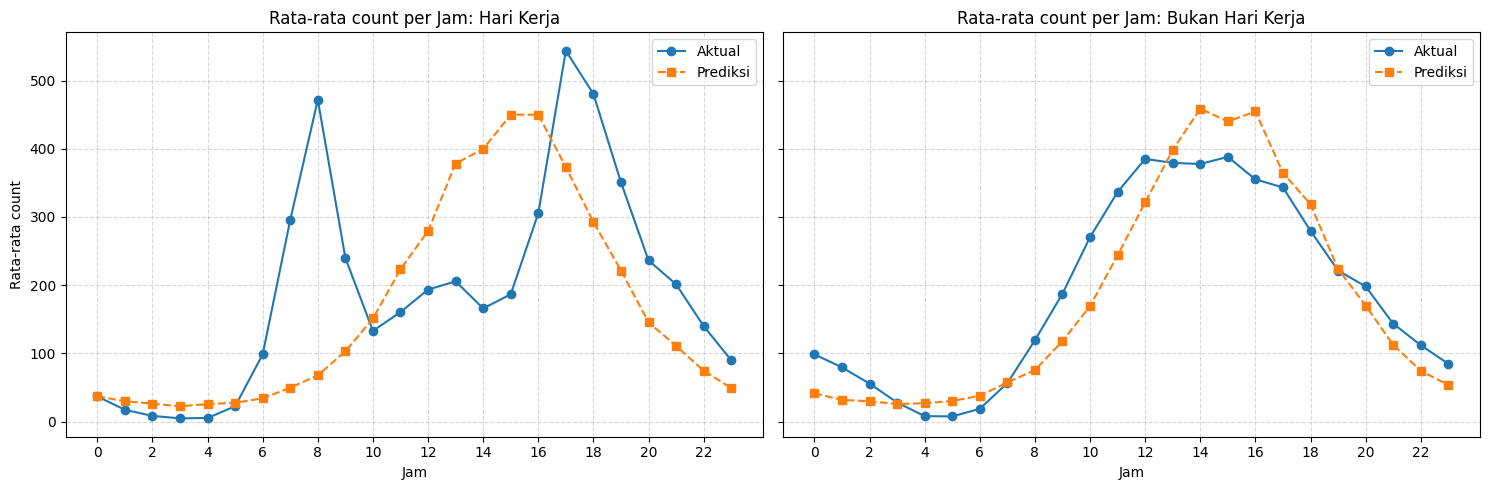

In [30]:
hasil = pd.DataFrame({
    'hour': df.loc[X_test.index, 'hour'].values,
    'workingday': X_test['workingday'].values,
    'aktual': y_original_test.values,
    'prediksi': y_pred
})

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (kode, nama) in zip(axes, [(1, 'Hari Kerja'), (0, 'Bukan Hari Kerja')]):
    rata = hasil[hasil['workingday'] == kode].groupby('hour')[['aktual', 'prediksi']].mean()
    ax.plot(rata.index, rata['aktual'], marker='o', label='Aktual')
    ax.plot(rata.index, rata['prediksi'], marker='s', linestyle='--', label='Prediksi')
    ax.set_title(f'Rata-rata count per Jam: {nama}')
    ax.set_xlabel('Jam')
    ax.set_xticks(range(0, 24, 2))
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()
axes[0].set_ylabel('Rata-rata count')
plt.tight_layout()
plt.show()

# **Kesimpulan Pemodelan**

1. Dataset **Bike Sharing Demand** digunakan untuk membangun model **Regresi Linear Berganda** dengan target `count` (ditransformasi `log1p`).
2. Fokus latihan, yaitu **manipulasi data waktu**, dilakukan dengan mengekstrak `hour`, `month`, `year`, dan `dayofweek` dari `datetime`, lalu merepresentasikan jam dan bulan secara **siklik** (sin/cos).
3. Kolom `casual` dan `registered` dibuang untuk mencegah **data leakage**, dan `atemp` dibuang karena **multikolinearitas** dengan `temp`.
4. Model dievaluasi dengan **MSE, RMSE, R², dan RMSLE** pada data uji.
5. Dari koefisien, faktor yang paling berpengaruh dapat dibaca dari besarnya koefisien (jam, tahun, suhu, dan kondisi cuaca).
6. Analisis residual menunjukkan keterbatasan asumsi linearitas dan varians konstan.

### Keterbatasan dan Langkah Lanjutan
* Pola permintaan sepeda bersifat **non-linear** dan penuh **interaksi** (misalnya jam × hari kerja). Regresi linear tidak menangkapnya sepenuhnya.
* Perbaikan yang dapat dicoba: fitur interaksi (`hour × workingday`), regresi polinomial, **Ridge/Lasso**, atau model berbasis pohon seperti **Random Forest / Gradient Boosting**.
* Pembagian data secara kronologis lebih realistis untuk data deret waktu.